## 1. Imports and Project Setup


In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold, KFold, TimeSeriesSplit
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import adfuller

# Support execution with either the project root or notebooks/ as the working directory.
project_dir = Path.cwd().resolve()
if not (project_dir / "data" / "raw" / "combined_gee_pm25.csv").exists():
    project_dir = project_dir.parent
if not (project_dir / "data" / "raw" / "combined_gee_pm25.csv").exists():
    raise FileNotFoundError("Could not locate data/raw/combined_gee_pm25.csv from the current directory.")

figures_dir = project_dir / "figures"
exploration_dir = project_dir / "results" / "exploration"
processed_dir = project_dir / "data" / "processed"
fold_dir = project_dir / "folds"
for output_dir in (figures_dir, exploration_dir, processed_dir, fold_dir):
    output_dir.mkdir(parents=True, exist_ok=True)


## 2. Dataset Loading and Initial Exploration


In [2]:
df = pd.read_csv(project_dir / "data" / "raw" / "combined_gee_pm25.csv")
df_raw = df.copy()

df.info()

display(df.head())

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

for column in df.columns:
    print(column)

display(df.dtypes)


<class 'pandas.DataFrame'>
RangeIndex: 41718 entries, 0 to 41717
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 41718 non-null  str    
 1   datetime_utc         41718 non-null  str    
 2   id                   41718 non-null  int64  
 3   latitude             41718 non-null  float64
 4   longitude            41718 non-null  float64
 5   temperature_celsius  41718 non-null  float64
 6   pressure_mb          41718 non-null  float64
 7   wind_u               41718 non-null  float64
 8   wind_v               41718 non-null  float64
 9   NO2                  39308 non-null  float64
 10  CO                   39308 non-null  float64
 11  O3                   39267 non-null  float64
 12  AOD                  41718 non-null  float64
 13  pm25                 41718 non-null  float64
 14  sensor_name          41718 non-null  str    
dtypes: float64(11), int64(1), str(3)
memory usage: 

,date,datetime_utc,id,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25,sensor_name
0,2016-11-25,2016-11-25 00:00:00,1,38.788056,-0.697222,6.493180,946.288660,0.230240,0.735303,NaN,NaN,NaN,0.1110,2.750000,ONTINYENT
1,2016-11-25,2016-11-25 00:00:00,36,39.945278,-0.056389,9.251236,993.626994,0.783218,-0.592618,NaN,NaN,NaN,0.0220,11.666667,ALMASSORA-C. P. OCHANDO
2,2016-11-30,2016-11-30 00:00:00,35,40.051944,-0.189722,10.044782,981.911432,-2.211047,-1.568971,NaN,NaN,NaN,0.2380,2.400000,ALCORA
3,2016-11-30,2016-11-30 00:00:00,37,40.062222,0.072778,12.299584,1008.794766,-3.236886,-2.804465,NaN,NaN,NaN,0.2480,2.600000,BENICASSIM
4,2016-12-02,2016-12-02 00:00:00,1,38.788056,-0.697222,9.350630,953.114180,0.953454,0.293060,NaN,NaN,NaN,0.0755,2.750000,ONTINYENT


Number of rows: 41718
Number of columns: 15
date
datetime_utc
id
latitude
longitude
temperature_celsius
pressure_mb
wind_u
wind_v
NO2
CO
O3
AOD
pm25
sensor_name


date                       str
datetime_utc               str
id                       int64
latitude               float64
longitude              float64
temperature_celsius    float64
pressure_mb            float64
wind_u                 float64
wind_v                 float64
NO2                    float64
CO                     float64
O3                     float64
AOD                    float64
pm25                   float64
sensor_name                str
dtype: object

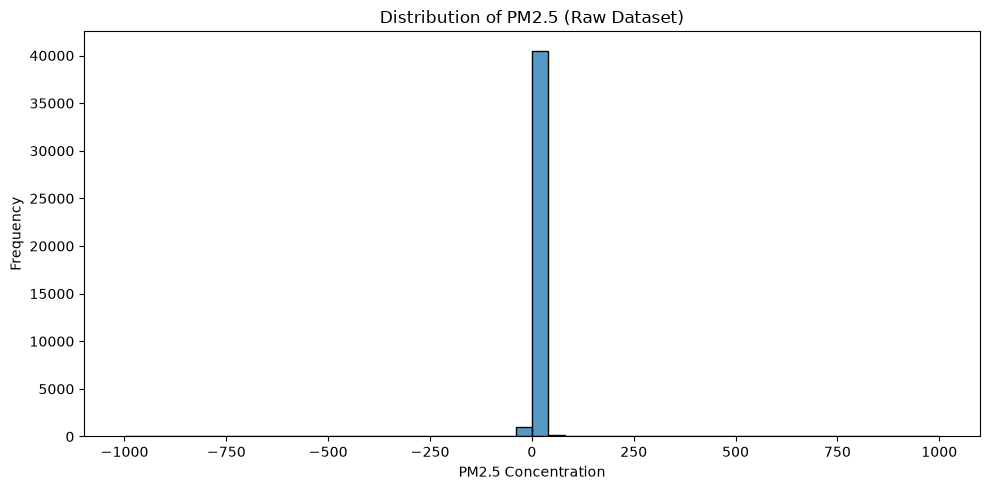

In [3]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="pm25", bins=50)
plt.title("Distribution of PM2.5 (Raw Dataset)")
plt.xlabel("PM2.5 Concentration")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(figures_dir / "pm25_distribution.png", dpi=300)
plt.show()


## 3. Data Cleaning and Quality Checks


In [4]:
duplicate_count = df.duplicated().sum()

duplicate_percentage = (duplicate_count / len(df)) * 100

duplicate_summary = pd.DataFrame({
    "Metric": ["Duplicate Rows", "Duplicate Percentage"],
    "Value": [duplicate_count, duplicate_percentage]
})

display(duplicate_summary)


,Metric,Value
0,Duplicate Rows,0.0
1,Duplicate Percentage,0.0


In [5]:
df["date"] = pd.to_datetime(df["date"])
df["datetime_utc"] = pd.to_datetime(df["datetime_utc"])


In [6]:
# Keep only valid PM2.5 values
df_valid = df[
    (df["pm25"] > 0) &
    (df["pm25"] < 500)
].copy()

print("Original dataset:", len(df))
print("Valid dataset:", len(df_valid))

invalid_pm25 = df[
    (df["pm25"] <= 0) | (df["pm25"] >= 500)
]

print("Number of invalid PM2.5 values:", len(invalid_pm25))

print("Values <= 0:", (df["pm25"] <= 0).sum())

print("Values >= 500:", (df["pm25"] >= 500).sum())

display(invalid_pm25.head(10))

Q1 = df["pm25"].quantile(0.25)
Q3 = df["pm25"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

outliers = df[
    (df["pm25"] < lower_limit) |
    (df["pm25"] > upper_limit)
]

print("Number of statistical outliers:", len(outliers))

# Keep the year feature on the raw frame; df_valid remains the original valid-only exploration copy.
df["year"] = df["date"].dt.year


Original dataset: 41718
Valid dataset: 40983
Number of invalid PM2.5 values: 735
Values <= 0: 727
Values >= 500: 8


,date,datetime_utc,id,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25,sensor_name
364,2017-03-19,2017-03-19,72,43.453462,5.467102,13.655931,977.057090,2.196543,-2.994981,NaN,NaN,NaN,0.0375,0.000000,FR03030
634,2017-05-10,2017-05-10,35,40.051944,-0.189722,16.732814,957.365928,-0.594108,0.743742,NaN,NaN,NaN,0.3520,0.000000,ALCORA
1495,2017-07-20,2017-07-20,35,40.051944,-0.189722,23.862784,965.181392,-1.469540,0.039181,NaN,NaN,NaN,0.3970,0.000000,ALCORA
3809,2019-07-03,2019-07-03,0,38.454722,-0.803333,24.905848,952.248787,-1.939435,0.436301,0.000083,0.025917,0.142272,0.1475,-926.714286,ELDA-LACY
3810,2019-07-03,2019-07-03,1,38.788056,-0.697222,24.581223,950.193371,-1.693586,-0.614155,0.000091,0.025281,0.142404,0.1420,-999.000000,ONTINYENT
3811,2019-07-03,2019-07-03,6,39.456111,-0.375833,26.768641,1007.720454,-1.541405,-0.284565,0.000106,0.029441,0.143659,0.1485,-999.000000,VALÈNCIA-PISTA DE SILLA
3812,2019-07-03,2019-07-03,8,39.457500,-0.342778,26.768641,1007.720454,-1.541405,-0.284565,0.000106,0.029441,0.143659,0.1485,-926.928571,VALÈNCIA - AVD. FRANCIA
3813,2019-07-03,2019-07-03,5,39.480300,-0.336400,26.768641,1007.720454,-1.541405,-0.284565,0.000106,0.029441,0.143659,0.1485,-926.500000,VALÈNCIA-POLITÈCNIC
3814,2019-07-03,2019-07-03,12,39.481111,-0.447222,26.248947,1000.832121,-1.506371,-0.234231,0.000118,0.029680,0.143451,0.1480,-926.785714,QUART DE POBLET
3815,2019-07-03,2019-07-03,10,39.564722,-0.625556,25.276210,983.598371,-1.519595,0.013246,0.000112,0.025907,0.143288,0.1430,-927.000000,VILAMARXANT


Q1: 4.5
Q3: 12.0
IQR: 7.5
Lower limit: -6.75
Upper limit: 23.25
Number of statistical outliers: 1634


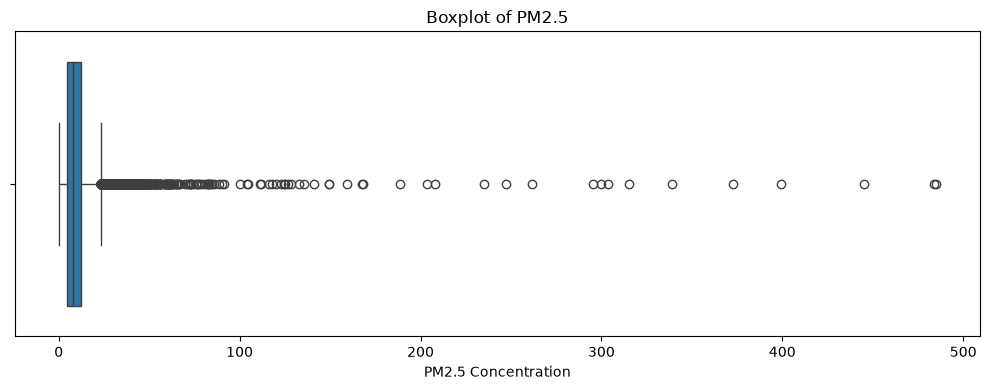

In [7]:

fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(x=df_valid["pm25"], ax=ax)

ax.set_title("Boxplot of PM2.5")
ax.set_xlabel("PM2.5 Concentration")

plt.tight_layout()

# Save figure
fig.savefig(
    figures_dir / "pm25_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


The full-dataset median imputation below is retained only for exploratory quality checks. It is not used for model training; modeling imputation is fitted after the chronological split.


In [8]:
df_clean = df[(df["pm25"] > 0) & (df["pm25"] < 500)].copy()

print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

missing_values = df_clean.isnull().sum()

print(missing_values)

numerical_columns = [
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v",
    "NO2",
    "CO",
    "O3",
    "AOD"
]

for column in numerical_columns:
    df_clean[column] = df_clean[column].fillna(df_clean[column].median())

print("Missing values after cleaning:")
print(df_clean.isnull().sum())


Original dataset: (41718, 16)
Cleaned dataset: (40983, 16)
date                      0
datetime_utc              0
id                        0
latitude                  0
longitude                 0
temperature_celsius       0
pressure_mb               0
wind_u                    0
wind_v                    0
NO2                    2407
CO                     2407
O3                     2448
AOD                       0
pm25                      0
sensor_name               0
year                      0
dtype: int64
Missing values after cleaning:
date                   0
datetime_utc           0
id                     0
latitude               0
longitude              0
temperature_celsius    0
pressure_mb            0
wind_u                 0
wind_v                 0
NO2                    0
CO                     0
O3                     0
AOD                    0
pm25                   0
sensor_name            0
year                   0
dtype: int64


In [9]:
print("Number of rows:", df_clean.shape[0])
print("Number of columns:", df_clean.shape[1])

print(df_clean.dtypes)

df_clean = df_clean.sort_values(
    by=["date", "sensor_name"]
).reset_index(drop=True)

display(df_clean.head(10))


Number of rows: 40983
Number of columns: 16
date                   datetime64[us]
datetime_utc           datetime64[us]
id                              int64
latitude                      float64
longitude                     float64
temperature_celsius           float64
pressure_mb                   float64
wind_u                        float64
wind_v                        float64
NO2                           float64
CO                            float64
O3                            float64
AOD                           float64
pm25                          float64
sensor_name                       str
year                            int32
dtype: object


,date,datetime_utc,id,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25,sensor_name,year
0,2016-11-25,2016-11-25,36,39.945278,-0.056389,9.251236,993.626994,0.783218,-0.592618,0.000086,0.031412,0.140472,0.022000,11.666667,ALMASSORA-C. P. OCHANDO,2016
1,2016-11-25,2016-11-25,1,38.788056,-0.697222,6.493180,946.288660,0.230240,0.735303,0.000086,0.031412,0.140472,0.111000,2.750000,ONTINYENT,2016
2,2016-11-30,2016-11-30,35,40.051944,-0.189722,10.044782,981.911432,-2.211047,-1.568971,0.000086,0.031412,0.140472,0.238000,2.400000,ALCORA,2016
3,2016-11-30,2016-11-30,37,40.062222,0.072778,12.299584,1008.794766,-3.236886,-2.804465,0.000086,0.031412,0.140472,0.248000,2.600000,BENICASSIM,2016
4,2016-12-02,2016-12-02,102,39.705278,-0.336667,9.225549,967.947096,0.494551,-0.294933,0.000086,0.031412,0.140472,0.095500,6.200000,ALBALAT DELS TARONGERS,2016
5,2016-12-02,2016-12-02,35,40.051944,-0.189722,9.058394,970.977930,0.574263,-0.443167,0.000086,0.031412,0.140472,0.055000,5.333333,ALCORA,2016
6,2016-12-02,2016-12-02,101,39.782222,-0.359167,9.225549,967.947096,0.494551,-0.294933,0.000086,0.031412,0.140472,0.095500,7.800000,ALGAR DE PALÀNCIA,2016
7,2016-12-02,2016-12-02,36,39.945278,-0.056389,11.065637,1000.462513,0.543135,-0.195893,0.000086,0.031412,0.140472,0.074500,9.333333,ALMASSORA-C. P. OCHANDO,2016
8,2016-12-02,2016-12-02,37,40.062222,0.072778,11.278934,997.458346,0.672448,-0.052847,0.000086,0.031412,0.140472,0.073667,4.000000,BENICASSIM,2016
9,2016-12-02,2016-12-02,38,39.892222,-0.065000,11.667769,1006.780430,0.601647,0.021392,0.000086,0.031412,0.140472,0.113500,8.666667,BURRIANA,2016


In [10]:
duplicate_station_dates = df_clean.duplicated(
    subset=["sensor_name", "date"]
).sum()

print("Duplicate station-date records:", duplicate_station_dates)

duplicates = df_clean[
    df_clean.duplicated(
        subset=["sensor_name", "date"],
        keep=False
    )
].sort_values(["sensor_name", "date"])

display(duplicates)

display(duplicates.groupby(
    ["sensor_name", "date"]
).agg({
    "id": "nunique",
    "pm25": ["count", "mean", "min", "max"],
    "latitude": "nunique",
    "longitude": "nunique"
}))

print("Missing sensor names:", df_clean["sensor_name"].isnull().sum())

print("Missing IDs:", df_clean["id"].isnull().sum())


Duplicate station-date records: 2


,date,datetime_utc,id,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25,sensor_name,year
28357,2024-08-30,2024-08-30,105,38.057300,-1.204700,24.053120,991.021203,-0.206704,-0.795269,0.000083,0.033897,0.143295,0.218,11.665,MOLINA DE SEGURA,2024
28358,2024-08-30,2024-08-30,107,38.057373,-1.204813,24.053120,991.021203,-0.206704,-0.795269,0.000083,0.033897,0.143295,0.218,10.530,MOLINA DE SEGURA,2024
28364,2024-08-30,2024-08-30,109,37.992300,-1.145900,24.680073,997.004953,-0.606647,-1.348858,0.000075,0.035093,0.143506,0.228,11.680,SAN BASILIO,2024
28365,2024-08-30,2024-08-30,104,37.993611,-1.144722,24.680073,997.004953,-0.606647,-1.348858,0.000075,0.035093,0.143506,0.228,13.235,SAN BASILIO,2024


id  pm25                         latitude  \
                            nunique count     mean    min     max  nunique   
sensor_name      date                                                        
MOLINA DE SEGURA 2024-08-30       2     2  11.0975  10.53  11.665        2   
SAN BASILIO      2024-08-30       2     2  12.4575  11.68  13.235        2   

                            longitude  
                              nunique  
sensor_name      date                  
MOLINA DE SEGURA 2024-08-30         2  
SAN BASILIO      2024-08-30         2

Missing sensor names: 0
Missing IDs: 0


In [11]:
print("Invalid latitudes:", 
      ((df_valid["latitude"] < -90) | (df_valid["latitude"] > 90)).sum())

print("Invalid longitudes:", 
      ((df_valid["longitude"] < -180) | (df_valid["longitude"] > 180)).sum())


Invalid latitudes: 0
Invalid longitudes: 0


In [12]:
print("Original dataset rows:", len(df))

print("Missing PM2.5:", df["pm25"].isna().sum())

print("PM2.5 <= 0:", (df["pm25"] <= 0).sum())

print("PM2.5 >= 500:", (df["pm25"] >= 500).sum())

print("Valid dataset rows:", len(df_valid))

print("Total removed rows:", len(df) - len(df_valid))

cleaning_summary = pd.DataFrame({
    "Metric": [
        "Original observations",
        "Missing PM2.5",
        "PM2.5 <= 0",
        "PM2.5 >= 500",
        "Removed observations",
        "Valid observations",
        "Percentage removed"
    ],
    "Value": [
        len(df),
        df["pm25"].isna().sum(),
        (df["pm25"] <= 0).sum(),
        (df["pm25"] >= 500).sum(),
        len(df) - len(df_valid),
        len(df_valid),
        (len(df) - len(df_valid)) / len(df) * 100
    ]
})

cleaning_summary.to_csv(
    project_dir / "results" / "exploration" / "cleaning_summary.csv",
    index=False
)

print(cleaning_summary)


Original dataset rows: 41718
Missing PM2.5: 0
PM2.5 <= 0: 727
PM2.5 >= 500: 8
Valid dataset rows: 40983
Total removed rows: 735
                  Metric         Value
0  Original observations  41718.000000
1          Missing PM2.5      0.000000
2             PM2.5 <= 0    727.000000
3           PM2.5 >= 500      8.000000
4   Removed observations    735.000000
5     Valid observations  40983.000000
6     Percentage removed      1.761829


In [13]:
# Check complete duplicate rows
full_duplicates = df_valid.duplicated().sum()

# Check duplicate station/date combinations
station_date_duplicates = df_valid.duplicated(
    subset=["sensor_name", "date"]
).sum()

# Check duplicate ID/date combinations
id_date_duplicates = df_valid.duplicated(
    subset=["id", "date"]
).sum()

print("Complete duplicate rows:", full_duplicates)
print("Duplicate station/date combinations:", station_date_duplicates)
print("Duplicate ID/date combinations:", id_date_duplicates)

duplicate_summary = pd.DataFrame({
    "Check": [
        "Complete duplicate rows",
        "Duplicate station/date combinations",
        "Duplicate ID/date combinations"
    ],
    "Count": [
        df_valid.duplicated().sum(),
        df_valid.duplicated(
            subset=["sensor_name", "date"]
        ).sum(),
        df_valid.duplicated(
            subset=["id", "date"]
        ).sum()
    ]
})

duplicate_summary.to_csv(
    project_dir / "results" / "exploration" / "duplicate_summary.csv",
    index=False
)

print(duplicate_summary)


Complete duplicate rows: 0
Duplicate station/date combinations: 2
Duplicate ID/date combinations: 0
                                 Check  Count
0              Complete duplicate rows      0
1  Duplicate station/date combinations      2
2       Duplicate ID/date combinations      0


## 4. Statistical and Correlation Analysis


In [14]:
display(df_raw.describe(include="all"))


,date,datetime_utc,id,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25,sensor_name
count,41718,41718,41718.000000,41718.000000,41718.000000,41718.000000,41718.000000,41718.000000,41718.000000,39308.000000,39308.000000,39267.000000,41718.000000,41718.000000,41718
unique,2305,2305,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,94
top,2024-05-26,2024-05-26 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CENMO1
freq,42,42,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1047
mean,NaN,NaN,52.301333,39.032749,-0.472530,18.334932,993.702935,0.336047,-0.173491,0.000091,0.031560,0.143626,0.149101,9.099293,NaN
std,NaN,NaN,35.075280,2.225799,3.816180,6.382068,17.241096,2.524131,1.383497,0.000027,0.003891,0.014560,0.105844,23.141811,NaN
min,NaN,NaN,0.000000,36.133317,-5.663500,-1.279053,930.317065,-11.098723,-10.860048,0.000023,0.013058,0.103899,0.000000,-999.000000,NaN
25%,NaN,NaN,21.000000,36.841330,-3.612660,13.019105,987.757065,-0.992154,-0.720651,0.000075,0.029014,0.134057,0.080500,4.500000,NaN
50%,NaN,NaN,48.000000,39.448330,-0.406050,18.594874,997.641550,0.190988,0.047318,0.000086,0.031394,0.140472,0.128500,7.750000,NaN
75%,NaN,NaN,90.000000,40.051944,1.149600,23.863248,1005.290895,1.671555,0.663616,0.000101,0.033819,0.151126,0.195000,12.000000,NaN


In [15]:
display(df_raw["pm25"].describe())


count    41718.000000
mean         9.099293
std         23.141811
min       -999.000000
25%          4.500000
50%          7.750000
75%         12.000000
max       1000.000000
Name: pm25, dtype: float64

In [16]:
print("PM2.5 Mean:", df_raw["pm25"].mean())
print("PM2.5 Median:", df_raw["pm25"].median())

df_raw.describe().to_csv(exploration_dir / "descriptive_statistics.csv")


PM2.5 Mean: 9.099292541461026
PM2.5 Median: 7.75


In [17]:
df.describe().to_csv(exploration_dir / "descriptive_statistics_raw.csv")
print("Raw descriptive statistics saved.")


Raw descriptive statistics saved.


In [18]:
display(df_valid.describe())


,date,datetime_utc,id,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25
count,40983,40983,40983.000000,40983.000000,40983.000000,40983.000000,40983.000000,40983.000000,40983.000000,38576.000000,38576.000000,38535.000000,40983.000000,40983.000000
mean,2023-02-08 04:29:21.393748,2023-02-08 04:29:21.393748,52.725032,39.030362,-0.466409,18.271961,993.817385,0.343444,-0.178770,0.000092,0.031578,0.143550,0.148693,9.457765
min,2016-11-25 00:00:00,2016-11-25 00:00:00,0.000000,36.133317,-5.663500,-1.279053,930.317065,-11.098723,-10.860048,0.000023,0.013058,0.103899,0.000000,0.006667
25%,2021-09-04 00:00:00,2021-09-04 00:00:00,21.000000,36.841330,-3.612660,12.965739,987.986366,-0.984837,-0.730883,0.000075,0.029041,0.134019,0.080000,4.673864
50%,2023-09-13 00:00:00,2023-09-13 00:00:00,50.000000,39.448330,-0.406050,18.494734,997.728716,0.205846,0.042730,0.000086,0.031412,0.140472,0.128000,7.851176
75%,2024-12-10 00:00:00,2024-12-10 00:00:00,90.000000,40.051944,1.149600,23.787869,1005.366821,1.684241,0.661478,0.000101,0.033827,0.151048,0.194000,12.086667
max,2026-04-06 00:00:00,2026-04-06 00:00:00,109.000000,43.530297,9.136389,34.865831,1033.662176,9.661651,8.486383,0.000483,0.097613,0.229322,5.475000,484.981500
std,NaN,NaN,35.034045,2.231117,3.829059,6.386195,17.180014,2.527802,1.385553,0.000027,0.003893,0.014491,0.106137,9.729713


,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25
temperature_celsius,1.000000,-0.062345,-0.179202,0.337792,-0.055051,-0.125935,-0.320234,0.332200,-0.006029
pressure_mb,-0.062345,1.000000,-0.086242,-0.043925,0.166248,0.198497,-0.033617,0.017390,0.113291
wind_u,-0.179202,-0.086242,1.000000,-0.218186,-0.088724,0.032590,0.161986,-0.247343,-0.078638
wind_v,0.337792,-0.043925,-0.218186,1.000000,0.105886,-0.074568,-0.119938,0.163810,0.059479
NO2,-0.055051,0.166248,-0.088724,0.105886,1.000000,0.099938,-0.094424,-0.061578,0.159311
CO,-0.125935,0.198497,0.032590,-0.074568,0.099938,1.000000,0.210167,0.132956,0.041462
O3,-0.320234,-0.033617,0.161986,-0.119938,-0.094424,0.210167,1.000000,-0.009698,-0.087197
AOD,0.332200,0.017390,-0.247343,0.163810,-0.061578,0.132956,-0.009698,1.000000,0.094209
pm25,-0.006029,0.113291,-0.078638,0.059479,0.159311,0.041462,-0.087197,0.094209,1.000000


pm25                   1.000000
NO2                    0.159311
pressure_mb            0.113291
AOD                    0.094209
wind_v                 0.059479
CO                     0.041462
temperature_celsius   -0.006029
wind_u                -0.078638
O3                    -0.087197
Name: pm25, dtype: float64


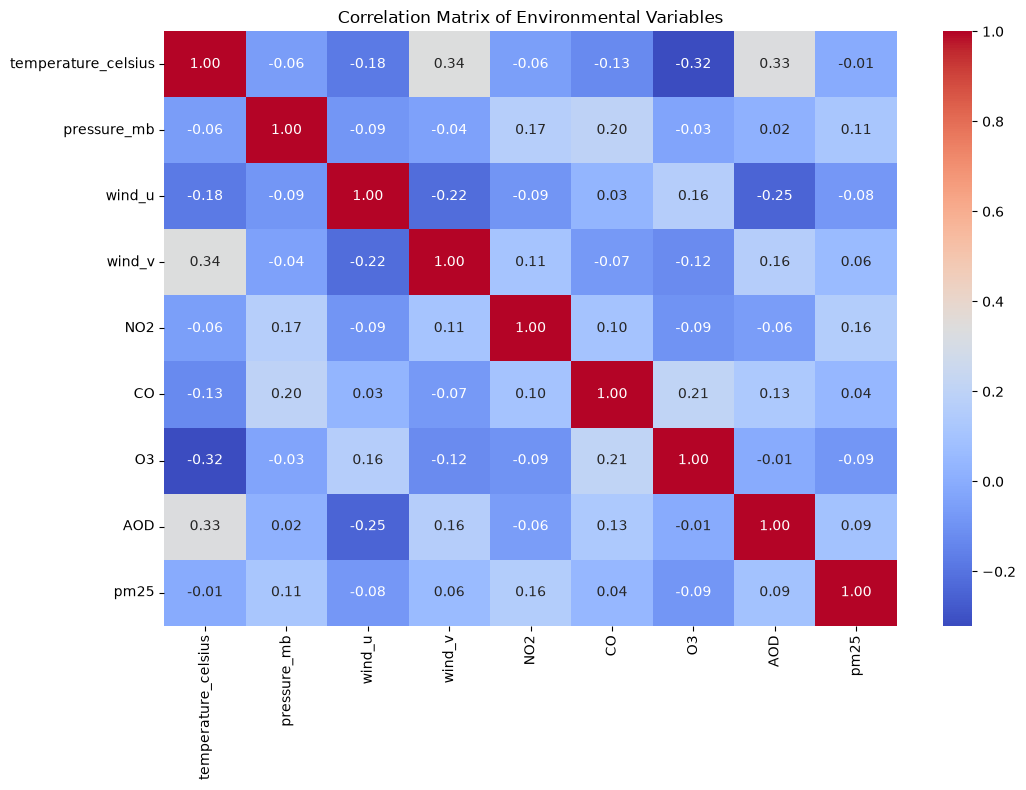

In [19]:
correlation_matrix = df_valid[
    [
        "temperature_celsius",
        "pressure_mb",
        "wind_u",
        "wind_v",
        "NO2",
        "CO",
        "O3",
        "AOD",
        "pm25"
    ]
].corr()

display(correlation_matrix)

pm25_correlation = correlation_matrix["pm25"].sort_values(
    ascending=False
)

print(pm25_correlation)

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Environmental Variables")

plt.tight_layout()

# Save figure
fig = plt.gcf()

fig.savefig(
    figures_dir / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


                     Metric      Value
0                  Skewness     17.829
1                  Kurtosis    651.672
2       Percentage above 25      2.984
3       Percentage above 50      0.285
4           Number above 25   1223.000
5           Number above 50    117.000
6  Total valid observations  40983.000
Spearman correlation with PM2.5:
NO2                    0.247
AOD                    0.180
pressure_mb            0.167
wind_u                -0.164
O3                    -0.135
latitude              -0.122
wind_v                 0.097
longitude             -0.089
temperature_celsius    0.064
CO                     0.036
Name: pm25, dtype: float64


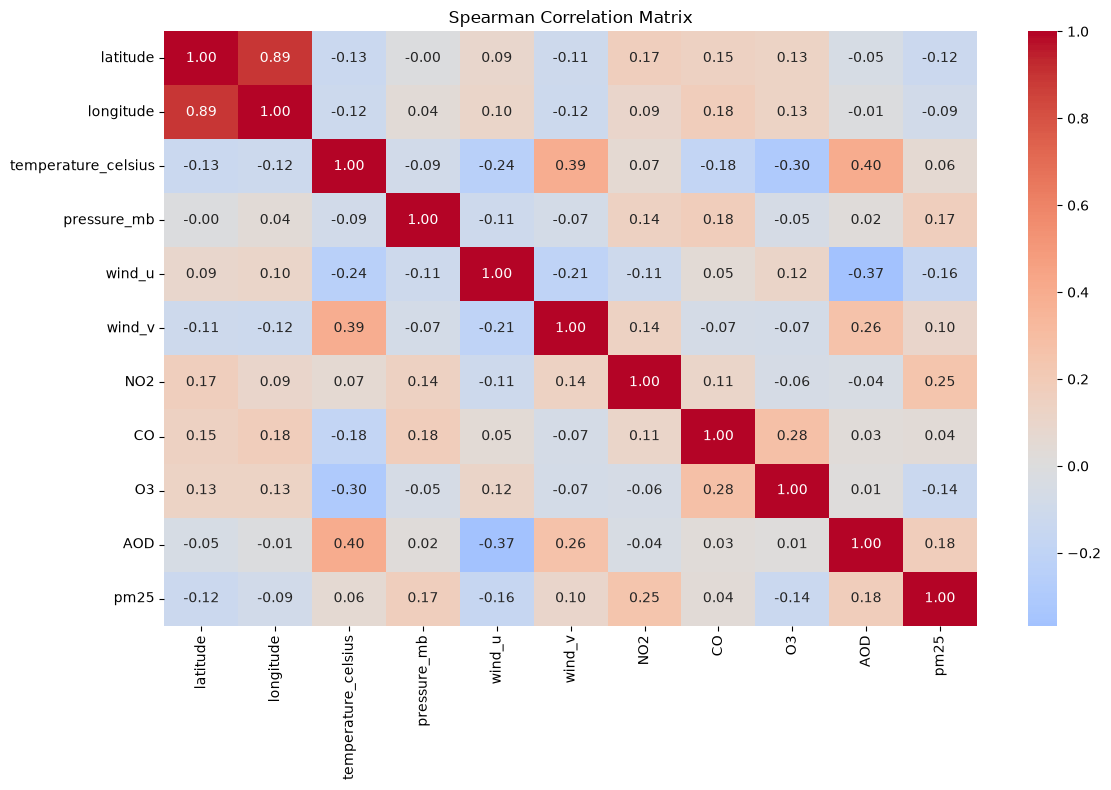

Spearman heatmap saved successfully.
File: C:\Users\Pc\Downloads\PM25-LIGHTGBM-PROJECT\PM25-LIGHTGBM-PROJECT\figures\spearman_correlation_heatmap.png
Highly correlated predictor pairs:
Empty DataFrame
Columns: [Feature 1, Feature 2, Spearman Correlation]
Index: []


In [20]:
pm25_stats = pd.DataFrame({
    "Metric": [
        "Skewness",
        "Kurtosis",
        "Percentage above 25",
        "Percentage above 50",
        "Number above 25",
        "Number above 50",
        "Total valid observations"
    ],
    "Value": [
        df_valid["pm25"].skew(),
        df_valid["pm25"].kurt(),
        (df_valid["pm25"] > 25).mean() * 100,
        (df_valid["pm25"] > 50).mean() * 100,
        (df_valid["pm25"] > 25).sum(),
        (df_valid["pm25"] > 50).sum(),
        len(df_valid)
    ]
})

print(pm25_stats.round(3))

# Select numerical columns
numeric_data = df_valid.select_dtypes(include="number").copy()

# Remove ID because it is an identifier, not a measurement
numeric_data = numeric_data.drop(columns=["id"], errors="ignore")

# Calculate Spearman correlation
spearman_matrix = numeric_data.corr(method="spearman")

# Show correlations with PM2.5
spearman_pm25 = (
    spearman_matrix["pm25"]
    .drop("pm25")
    .sort_values(key=abs, ascending=False)
)

print("Spearman correlation with PM2.5:")
print(spearman_pm25.round(3))

plt.figure(figsize=(12, 8))

sns.heatmap(
    spearman_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Spearman Correlation Matrix")
plt.tight_layout()

plt.savefig(
    figures_dir / "spearman_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Spearman heatmap saved successfully.")
print("File:", figures_dir / "spearman_correlation_heatmap.png")

# Remove PM2.5 because we only want to compare predictors
predictor_corr = spearman_matrix.drop(
    index="pm25",
    columns="pm25"
)

# Keep only the upper triangle to avoid duplicate pairs
upper_triangle = predictor_corr.where(
    np.triu(
        np.ones(predictor_corr.shape),
        k=1
    ).astype(bool)
)

# Find highly correlated pairs
high_corr_pairs = upper_triangle.stack().reset_index()

high_corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Spearman Correlation"
]

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Spearman Correlation"].abs() > 0.9
]

print("Highly correlated predictor pairs:")
print(high_corr_pairs)


In [21]:
df_season = df_valid.copy()

df_season["date"] = pd.to_datetime(df_season["date"])

# Assign seasons
df_season["season"] = df_season["date"].dt.month.map({
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Autumn",
    10: "Autumn",
    11: "Autumn"
})

variables = [
    "pm25", "AOD", "NO2", "CO", "O3",
    "temperature_celsius", "wind_u", "wind_v"
]

# Calculate correlations separately for each season
seasonal_results = []

for season, group in df_season.groupby("season"):

    corr = group[variables].corr(method="spearman")

    pm25_corr = corr["pm25"].drop("pm25")

    for variable, value in pm25_corr.items():
        seasonal_results.append({
            "Season": season,
            "Variable": variable,
            "Correlation": value
        })

seasonal_corr = pd.DataFrame(seasonal_results)

print("Seasonal Spearman correlations with PM2.5:")
print(seasonal_corr.pivot(
    index="Variable",
    columns="Season",
    values="Correlation"
).round(3))

seasonal_corr_pivot = seasonal_corr.pivot(
    index="Variable",
    columns="Season",
    values="Correlation"
)

seasonal_corr_pivot.to_csv(
    project_dir / "results" / "exploration" / "seasonal_correlations.csv"
)

print("Seasonal correlation results saved successfully.")


Seasonal Spearman correlations with PM2.5:
Season               Autumn  Spring  Summer  Winter
Variable                                           
AOD                   0.214   0.162   0.209   0.250
CO                   -0.032   0.008   0.187   0.016
NO2                   0.209   0.249   0.197   0.353
O3                   -0.181  -0.158  -0.166  -0.129
temperature_celsius   0.079   0.092   0.244  -0.041
wind_u               -0.177  -0.214  -0.061  -0.334
wind_v                0.143   0.092   0.075   0.153
Seasonal correlation results saved successfully.


In [22]:
df_wind = df_valid.copy()

# Calculate wind speed
df_wind["wind_speed"] = np.sqrt(
    df_wind["wind_u"]**2 +
    df_wind["wind_v"]**2
)

# Divide wind speed into four groups
df_wind["wind_group"] = pd.qcut(
    df_wind["wind_speed"],
    q=4,
    labels=["Low", "Medium-Low", "Medium-High", "High"]
)

# Calculate Spearman correlation for each group
wind_aod_corr = (
    df_wind.groupby("wind_group", observed=True)
    .apply(
        lambda group: group["pm25"].corr(
            group["AOD"],
            method="spearman"
        )
    )
)

print("PM2.5-AOD correlation by wind speed:")
print(wind_aod_corr.round(3))

wind_aod_corr_df = wind_aod_corr.reset_index()

wind_aod_corr_df.columns = [
    "Wind Speed Group",
    "PM2.5-AOD Spearman Correlation"
]

wind_aod_corr_df.to_csv(
    project_dir / "results" / "exploration" / "wind_aod_correlation.csv",
    index=False
)

print("Wind-AOD correlation results saved successfully.")


PM2.5-AOD correlation by wind speed:
wind_group
Low            0.116
Medium-Low     0.089
Medium-High    0.185
High           0.304
dtype: float64
Wind-AOD correlation results saved successfully.


In [23]:
# Select numerical columns
numeric_columns = df_valid.select_dtypes(include="number").columns

# Calculate descriptive statistics
exploratory_stats = df_valid[numeric_columns].describe().T

# Add skewness and kurtosis
exploratory_stats["skewness"] = df_valid[numeric_columns].skew()
exploratory_stats["kurtosis"] = df_valid[numeric_columns].kurt()

# Display results
print(exploratory_stats.round(3))

exploratory_stats.to_csv(
    project_dir / "results" / "exploration" / "Exploratory_Data.csv"
)

print("Exploratory_Data.csv saved successfully!")

print(exploratory_stats.shape)

print(
    (project_dir / "results" / "exploration" / "Exploratory_Data.csv").exists()
)


                       count     mean     std      min      25%      50%  \
id                   40983.0   52.725  35.034    0.000   21.000   50.000   
latitude             40983.0   39.030   2.231   36.133   36.841   39.448   
longitude            40983.0   -0.466   3.829   -5.663   -3.613   -0.406   
temperature_celsius  40983.0   18.272   6.386   -1.279   12.966   18.495   
pressure_mb          40983.0  993.817  17.180  930.317  987.986  997.729   
wind_u               40983.0    0.343   2.528  -11.099   -0.985    0.206   
wind_v               40983.0   -0.179   1.386  -10.860   -0.731    0.043   
NO2                  38576.0    0.000   0.000    0.000    0.000    0.000   
CO                   38576.0    0.032   0.004    0.013    0.029    0.031   
O3                   38535.0    0.144   0.014    0.104    0.134    0.140   
AOD                  40983.0    0.149   0.106    0.000    0.080    0.128   
pm25                 40983.0    9.458   9.730    0.007    4.674    7.851   

           

## 5. Temporal Exploration


In [24]:
print("First date:", df["date"].min())
print("Last date:", df["date"].max())

print("Number of unique dates:", df["date"].nunique())

yearly_records = df["year"].value_counts().sort_index()

print(yearly_records)


First date: 2016-11-25 00:00:00
Last date: 2026-04-06 00:00:00
Number of unique dates: 2305
year
2016     111
2017    2119
2018     252
2019    2140
2020    3249
2021    4754
2022    4983
2023    5430
2024    8960
2025    8172
2026    1548
Name: count, dtype: int64


First date: 2016-11-25 00:00:00
Last date: 2026-04-06 00:00:00
Date type: <class 'pandas.DatetimeIndex'>


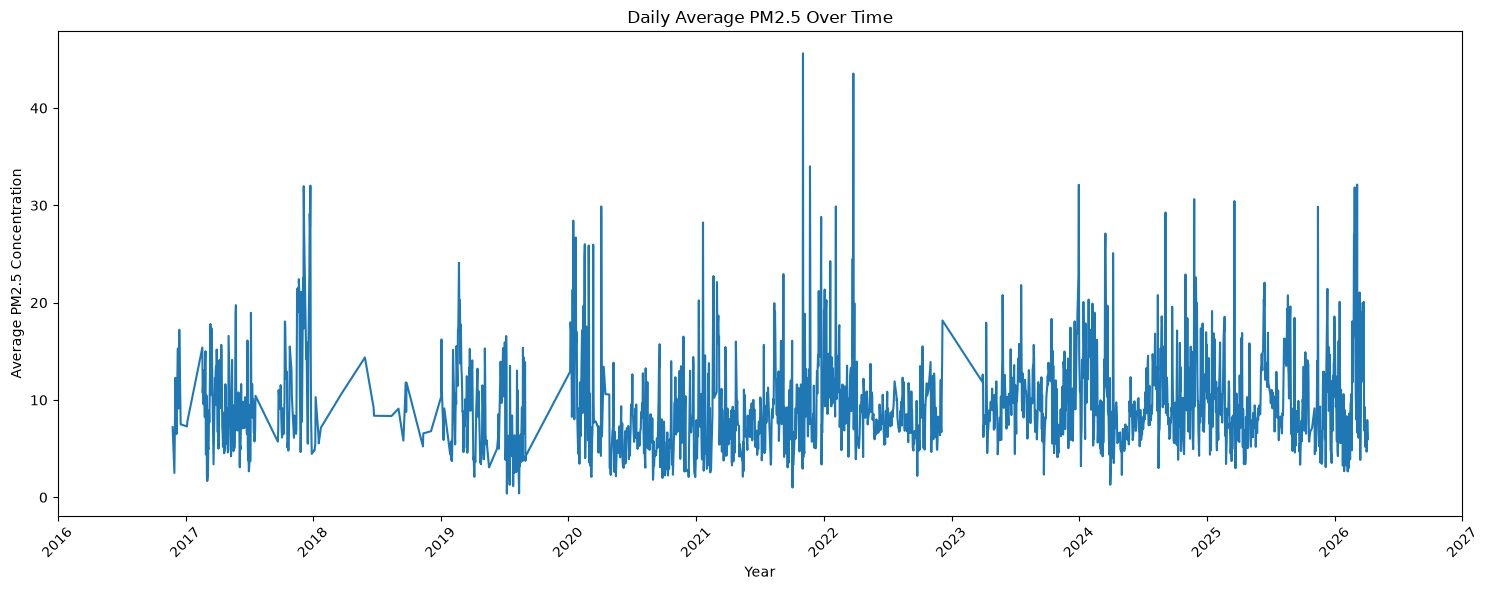

Daily PM2.5 figure saved successfully.


In [25]:
df_valid["date"] = pd.to_datetime(
    df_valid["date"],
    errors="coerce"
)

daily_pm25 = (
    df_valid
    .dropna(subset=["date"])
    .groupby("date")["pm25"]
    .mean()
    .sort_index()
)

print("First date:", daily_pm25.index.min())
print("Last date:", daily_pm25.index.max())
print("Date type:", type(daily_pm25.index))


fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    daily_pm25.index,
    daily_pm25.values
)

ax.set_title("Daily Average PM2.5 Over Time")
ax.set_xlabel("Year")
ax.set_ylabel("Average PM2.5 Concentration")

# Display one tick every year
ax.xaxis.set_major_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# Set date limits
ax.set_xlim(
    pd.Timestamp("2016-01-01"),
    pd.Timestamp("2027-01-01")
)

plt.xticks(rotation=45)
plt.tight_layout()

# Save figure
fig.savefig(
    figures_dir / "daily_pm25_over_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Daily PM2.5 figure saved successfully.")


date
1     10.386266
2     11.278159
3      9.485719
4      7.697311
5      7.759310
6      9.086287
7      9.127772
8     10.543708
9      8.106971
10     9.035003
11    10.165274
12    11.149009
Name: pm25, dtype: float64


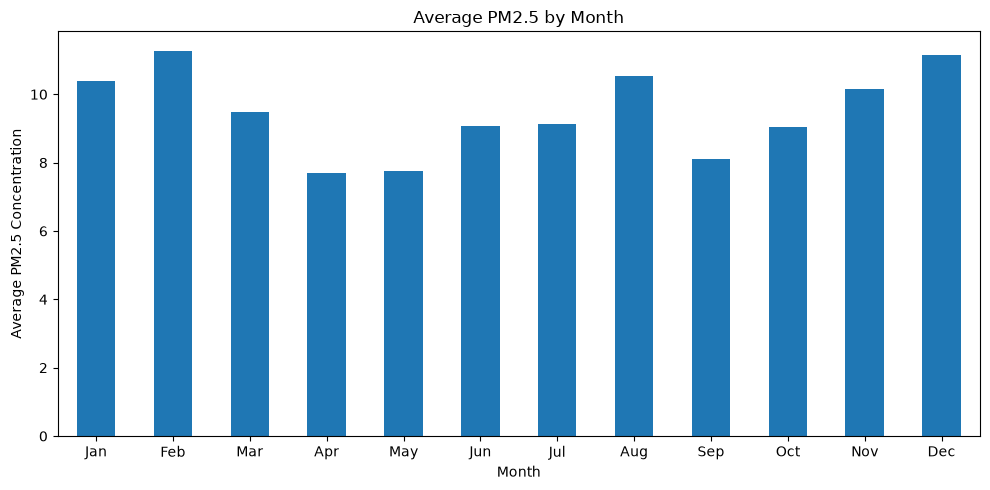

In [26]:

# Calculate average PM2.5 for each month
monthly_pm25 = df_valid.groupby(
    df_valid["date"].dt.month
)["pm25"].mean()

print(monthly_pm25)

# Create the bar chart
fig, ax = plt.subplots(figsize=(10, 5))

monthly_pm25.plot(kind="bar", ax=ax)

ax.set_title("Average PM2.5 by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Average PM2.5 Concentration")

ax.set_xticklabels([
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
], rotation=0)

plt.tight_layout()

# Save the figure
fig.savefig(
    figures_dir / "average_pm25_by_month.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [27]:
# Make sure date is in datetime format
df_valid["date"] = pd.to_datetime(df_valid["date"])

# Basic temporal information
print("First date:", df_valid["date"].min())
print("Last date:", df_valid["date"].max())

print("Number of unique dates:", df_valid["date"].nunique())

print("Number of observations:", len(df_valid))

# Generate a complete daily calendar
full_calendar = pd.date_range(
    start=df_valid["date"].min(),
    end=df_valid["date"].max(),
    freq="D"
)

# Extract dates present in the dataset
observed_dates = pd.DatetimeIndex(
    df_valid["date"].unique()
)

# Find missing dates
missing_dates = full_calendar.difference(observed_dates)

print("Expected calendar days:", len(full_calendar))
print("Observed dates:", len(observed_dates))
print("Missing dates:", len(missing_dates))

print("\nFirst 20 missing dates:")
print(missing_dates[:20])

missing_dates_df = pd.DataFrame({
    "Missing Date": missing_dates
})

missing_dates_df.to_csv(
    project_dir / "results" / "exploration" / "missing_dates.csv",
    index=False
)

print("Missing dates saved successfully!")


First date: 2016-11-25 00:00:00
Last date: 2026-04-06 00:00:00
Number of unique dates: 2299
Number of observations: 40983
Expected calendar days: 3420
Observed dates: 2299
Missing dates: 1121

First 20 missing dates:
DatetimeIndex(['2016-11-26', '2016-11-27', '2016-11-28', '2016-11-29',
               '2016-12-01', '2016-12-04', '2016-12-05', '2016-12-08',
               '2016-12-09', '2016-12-15', '2016-12-16', '2016-12-17',
               '2016-12-19', '2016-12-20', '2016-12-21', '2016-12-22',
               '2016-12-23', '2016-12-24', '2016-12-25', '2016-12-26'],
              dtype='datetime64[us]', freq=None)
Missing dates saved successfully!


In [28]:
daily_observations = (
    df_valid.groupby("date")
    .size()
    .rename("Number of Observations")
)

print("Daily observation statistics:")
print(daily_observations.describe().round(2))

print("\nFirst 10 dates:")
print(daily_observations.head(10))

daily_observations.describe().to_frame().to_csv(
    project_dir / "results" / "exploration" / "daily_observation_statistics.csv"
)

print("Daily observation statistics saved!")


Daily observation statistics:
count    2299.00
mean       17.83
std        10.17
min         1.00
25%        10.00
50%        16.00
75%        26.00
max        40.00
Name: Number of Observations, dtype: float64

First 10 dates:
date
2016-11-25     2
2016-11-30     2
2016-12-02    12
2016-12-03     9
2016-12-06    11
2016-12-07    13
2016-12-10    11
2016-12-11    13
2016-12-12    13
2016-12-13    12
Name: Number of Observations, dtype: int64
Daily observation statistics saved!


Monthly PM2.5 statistics:
                 mean     median        std  count
date                                              
2016-11-30   4.854167   2.675000   4.543929      4
2016-12-31  11.114897  10.200000   5.655116    107
2017-01-31   7.515675   6.183333   4.215305     24
2017-02-28  12.096893  10.864583   5.331851     95
2017-03-31   9.857475   7.818182  10.940029    164
2017-04-30   9.232362   7.100000   9.910862    206
2017-05-31   7.551486   6.428571   5.073475    215
2017-06-30   7.489942   6.285714   5.008540    395
2017-07-31   7.603972   6.475446   6.197072    284
2017-08-31        NaN        NaN        NaN      0
2017-09-30   9.033280   7.625000   4.362071    103
2017-10-31   9.795108   8.611111   5.912725    333
Monthly PM2.5 statistics saved successfully!


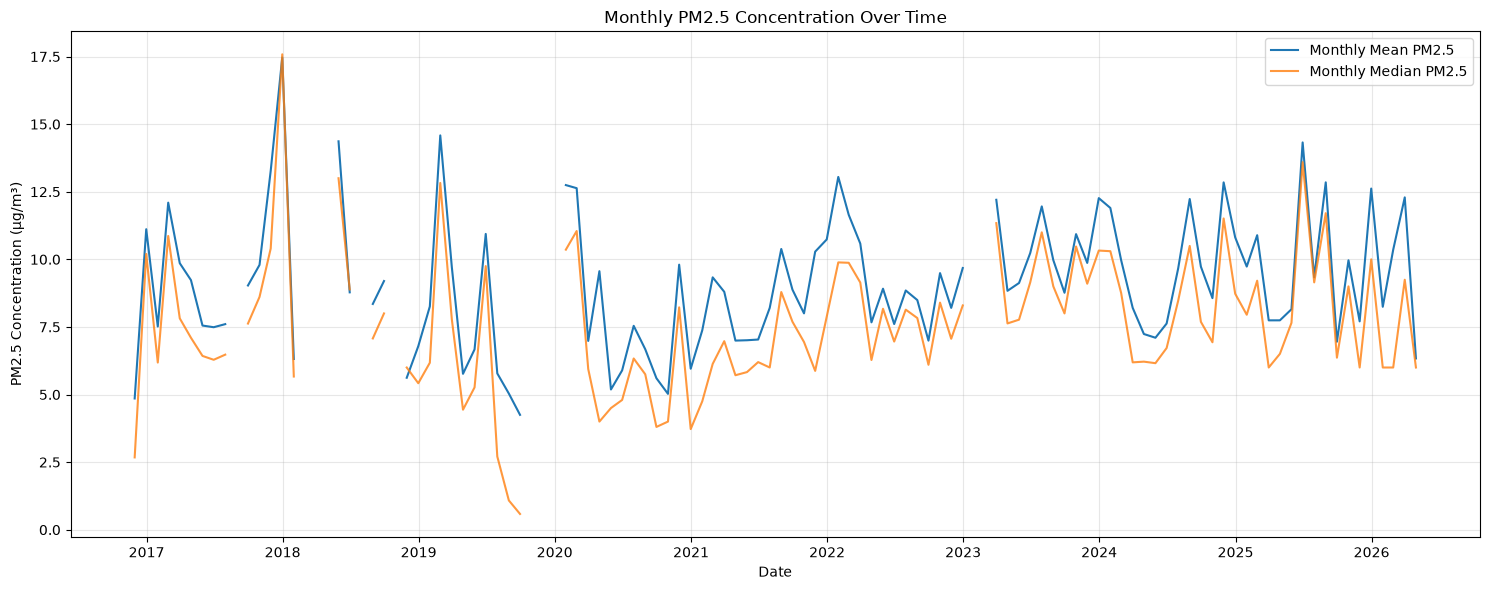

In [29]:
monthly_pm25 = (
    df_valid.set_index("date")["pm25"]
    .resample("ME")
    .agg(["mean", "median", "std", "count"])
)

print("Monthly PM2.5 statistics:")
print(monthly_pm25.head(12))

monthly_pm25.to_csv(
    project_dir / "results" / "exploration" / "monthly_pm25_statistics.csv"
)

print("Monthly PM2.5 statistics saved successfully!")


fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    monthly_pm25.index,
    monthly_pm25["mean"],
    label="Monthly Mean PM2.5"
)

ax.plot(
    monthly_pm25.index,
    monthly_pm25["median"],
    label="Monthly Median PM2.5",
    alpha=0.8
)

ax.set_title("Monthly PM2.5 Concentration Over Time")
ax.set_xlabel("Date")
ax.set_ylabel("PM2.5 Concentration (µg/m³)")

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()

fig.savefig(
    figures_dir / "monthly_pm25_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Annual PM2.5 statistics:
              mean  median     std  count
date                                     
2016-12-31  10.889  10.167   5.723    111
2017-12-31   9.460   7.667   7.746   2116
2018-12-31   7.880   7.019   4.867    252
2019-12-31   8.655   6.718   7.486   1772
2020-12-31   7.555   5.714   8.079   3247
2021-12-31   8.855   6.800  14.865   4746
2022-12-31   9.620   8.125  12.382   4954
2023-12-31  10.223   9.000   6.766   5400
2024-12-31   9.613   8.000   9.755   8688
2025-12-31   9.915   8.522   6.762   8149
2026-12-31   9.902   6.769  10.069   1548
Annual PM2.5 statistics saved successfully!


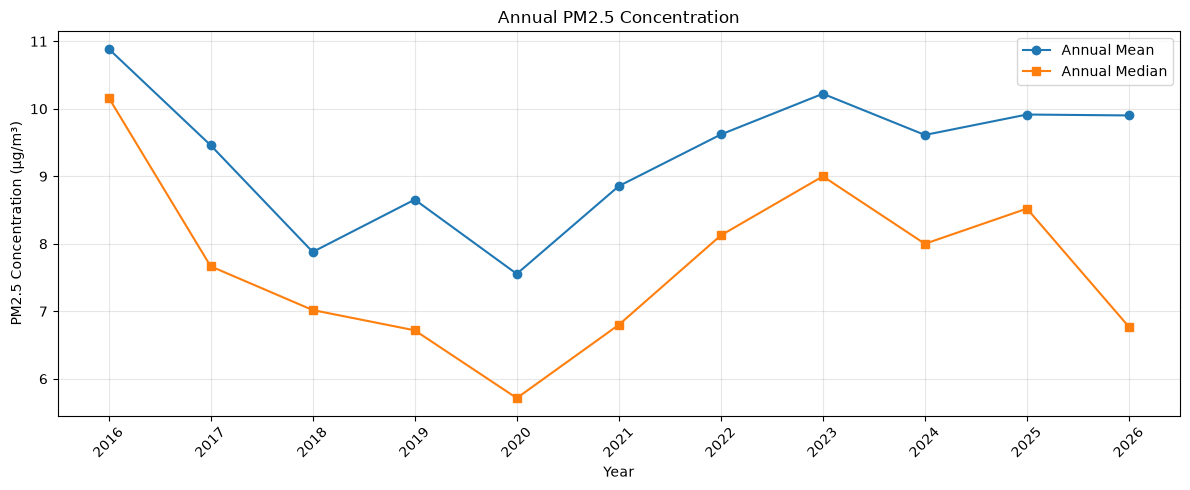

In [30]:
annual_pm25 = (
    df_valid.set_index("date")["pm25"]
    .resample("YE")
    .agg(["mean", "median", "std", "count"])
)

print("Annual PM2.5 statistics:")
print(annual_pm25.round(3))

annual_pm25.to_csv(
    project_dir / "results" / "exploration" / "annual_pm25_statistics.csv"
)

print("Annual PM2.5 statistics saved successfully!")

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    annual_pm25.index.year,
    annual_pm25["mean"],
    marker="o",
    label="Annual Mean"
)

ax.plot(
    annual_pm25.index.year,
    annual_pm25["median"],
    marker="s",
    label="Annual Median"
)

ax.set_title("Annual PM2.5 Concentration")
ax.set_xlabel("Year")
ax.set_ylabel("PM2.5 Concentration (µg/m³)")

ax.set_xticks(annual_pm25.index.year)
ax.tick_params(axis="x", rotation=45)

ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()

fig.savefig(
    figures_dir / "annual_pm25_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Seasonal PM2.5 statistics:
          mean  median     std  count
season                               
Winter  10.935   8.773  11.722   8938
Spring   8.251   6.833   7.403   9276
Summer   9.594   8.500   7.211  12766
Autumn   9.083   7.470  12.020  10003
Seasonal PM2.5 statistics saved successfully!


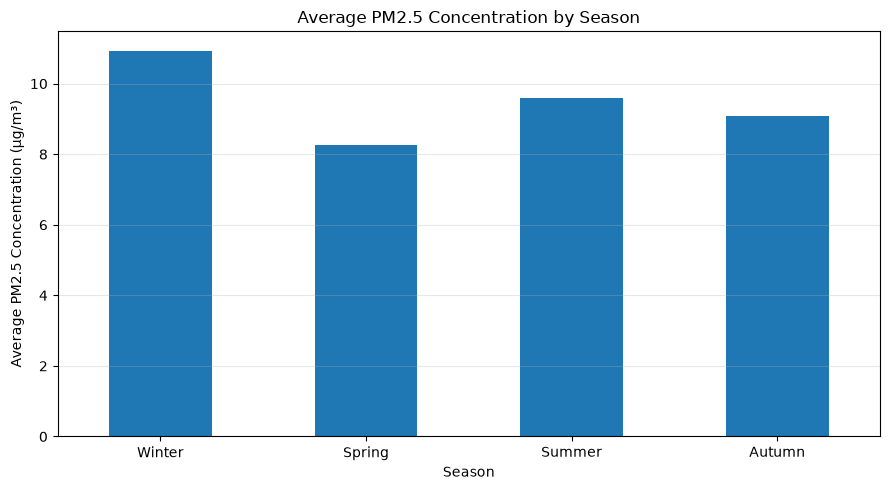

In [31]:
# Assign seasons based on the month
df_valid["season"] = df_valid["date"].dt.month.map({
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Autumn",
    10: "Autumn",
    11: "Autumn"
})

# Calculate seasonal statistics
seasonal_pm25 = (
    df_valid.groupby("season")["pm25"]
    .agg(["mean", "median", "std", "count"])
    .reindex(["Winter", "Spring", "Summer", "Autumn"])
)

print("Seasonal PM2.5 statistics:")
print(seasonal_pm25.round(3))

seasonal_pm25.to_csv(
    project_dir / "results" / "exploration" / "seasonal_pm25_statistics.csv"
)

print("Seasonal PM2.5 statistics saved successfully!")

fig, ax = plt.subplots(figsize=(9, 5))

seasonal_pm25["mean"].plot(
    kind="bar",
    ax=ax
)

ax.set_title("Average PM2.5 Concentration by Season")
ax.set_xlabel("Season")
ax.set_ylabel("Average PM2.5 Concentration (µg/m³)")

ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

fig.savefig(
    figures_dir / "seasonal_pm25_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Daily time series:
date
2016-11-25     7.208333
2016-11-26          NaN
2016-11-27          NaN
2016-11-28          NaN
2016-11-29          NaN
2016-11-30     2.500000
2016-12-01          NaN
2016-12-02     9.777778
2016-12-03    12.277778
2016-12-04          NaN
Freq: D, Name: pm25, dtype: float64

Total calendar days: 3420
Missing daily values: 1121
Missing values before: 1121
Missing values after: 0


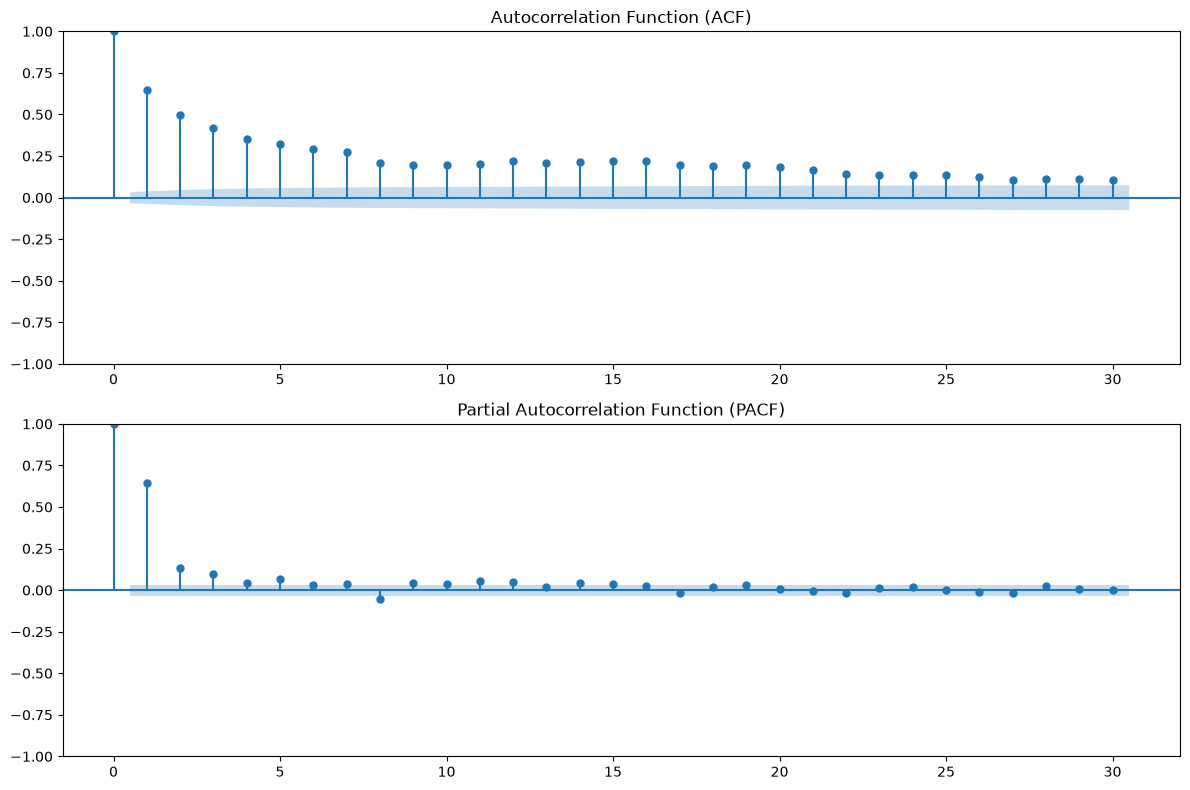

In [32]:
daily_pm25 = (
    df_valid.groupby("date")["pm25"]
    .mean()
    .sort_index()
)

# Add missing calendar dates
daily_pm25 = daily_pm25.asfreq("D")

print("Daily time series:")
print(daily_pm25.head(10))

print("\nTotal calendar days:", len(daily_pm25))
print("Missing daily values:", daily_pm25.isna().sum())

daily_pm25_acf = daily_pm25.interpolate(
    method="time",
    limit_area="inside"
)

print("Missing values before:", daily_pm25.isna().sum())
print("Missing values after:", daily_pm25_acf.isna().sum())


fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(
    daily_pm25_acf.dropna(),
    lags=30,
    ax=axes[0]
)

axes[0].set_title("Autocorrelation Function (ACF)")

plot_pacf(
    daily_pm25_acf.dropna(),
    lags=30,
    ax=axes[1],
    method="ywm"
)

axes[1].set_title("Partial Autocorrelation Function (PACF)")

plt.tight_layout()

fig.savefig(
    figures_dir / "acf_pacf_pm25.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [33]:

adf_result = adfuller(
    daily_pm25_acf.dropna(),
    autolag="AIC"
)

print("ADF Statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 6))
print("Number of Lags:", adf_result[2])
print("Number of Observations:", adf_result[3])

print("\nCritical Values:")
for key, value in adf_result[4].items():
    print(key, ":", round(value, 4))


ljung_box_result = acorr_ljungbox(
    daily_pm25_acf.dropna(),
    lags=[7, 14, 30],
    return_df=True
)

print("Ljung-Box Test Results:")
print(ljung_box_result.round(4))

adf_summary = pd.DataFrame({
    "Metric": [
        "ADF Statistic",
        "p-value",
        "Number of Lags",
        "Number of Observations"
    ],
    "Value": [
        adf_result[0],
        adf_result[1],
        adf_result[2],
        adf_result[3]
    ]
})

adf_summary.to_csv(
    project_dir / "results" / "exploration" / "adf_test.csv",
    index=False
)

ljung_box_result.to_csv(
    project_dir / "results" / "exploration" / "ljung_box_test.csv"
)

print("ADF and Ljung-Box results saved successfully!")


ADF Statistic: -8.5929
p-value: 0.0
Number of Lags: 15
Number of Observations: 3404

Critical Values:
1% : -3.4323
5% : -2.8624
10% : -2.5672
Ljung-Box Test Results:
      lb_stat  lb_pvalue
7   4216.6199        0.0
14  5251.9342        0.0
30  6662.9737        0.0
ADF and Ljung-Box results saved successfully!


C:\Users\Pc\AppData\Local\Temp\ipykernel_8512\408493909.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(


Number of continuous periods: 235

Longest 10 continuous periods:
     Start_Date   End_Date  Number_of_Days
date                                      
223  2024-07-31 2025-02-24             209
226  2025-07-01 2025-10-21             113
225  2025-03-09 2025-06-25             109
222  2024-05-16 2024-07-29              75
214  2023-10-24 2023-12-27              65
234  2026-01-04 2026-03-02              58
213  2023-08-27 2023-10-22              57
221  2024-04-01 2024-05-14              44
209  2023-06-04 2023-07-14              41
235  2026-03-04 2026-04-06              34
Start: 2024-07-31 00:00:00
End: 2025-02-24 00:00:00
Number of days: 209
Missing values: 0


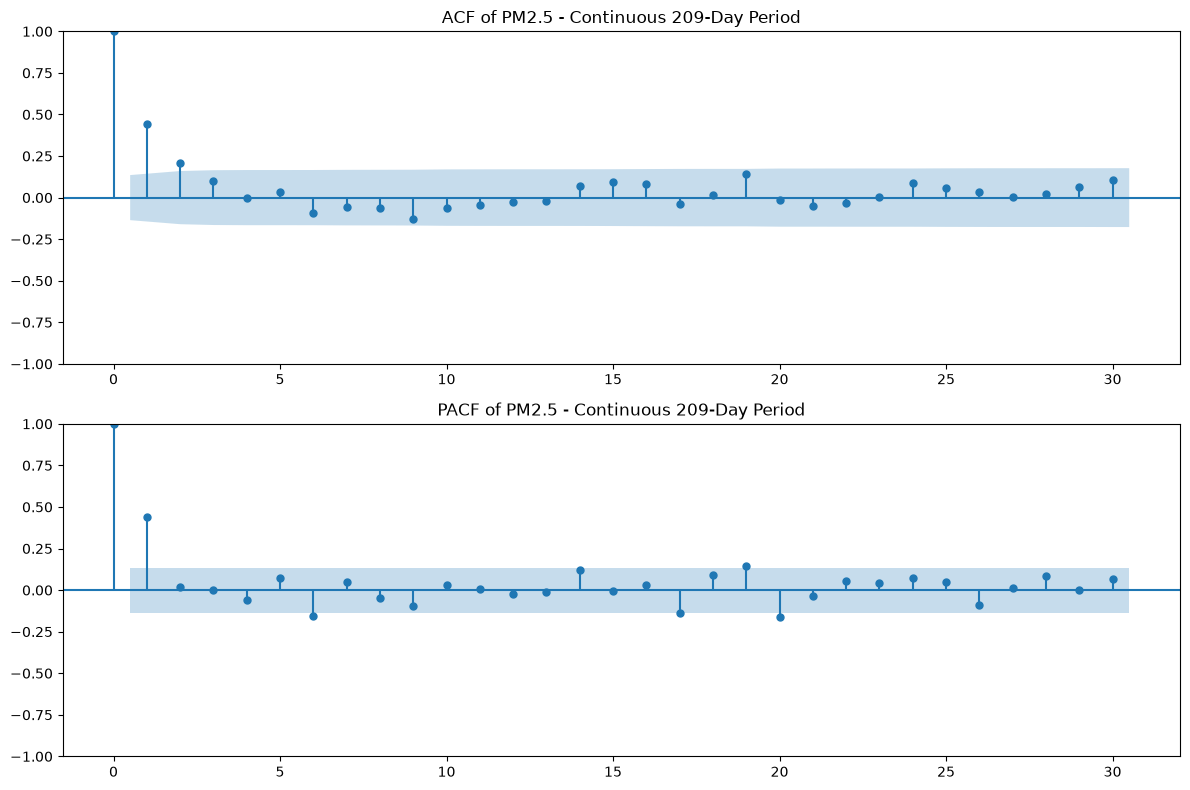

In [34]:
# Daily average PM2.5
daily_pm25 = (
    df_valid.groupby("date")["pm25"]
    .mean()
    .sort_index()
)

# Identify gaps between consecutive observed dates
date_difference = daily_pm25.index.to_series().diff()

# Start a new group whenever the gap is greater than one day
groups = date_difference.ne(pd.Timedelta(days=1)).cumsum()

# Find consecutive daily periods
continuous_periods = (
    daily_pm25.groupby(groups)
    .agg(
        Start_Date=lambda x: x.index.min(),
        End_Date=lambda x: x.index.max(),
        Number_of_Days="count"
    )
    .sort_values("Number_of_Days", ascending=False)
)

print("Number of continuous periods:", len(continuous_periods))

print("\nLongest 10 continuous periods:")
print(continuous_periods.head(10))

# Calculate groups of consecutive dates
date_difference = daily_pm25.index.to_series().diff()

groups = date_difference.ne(pd.Timedelta(days=1)).cumsum()

# Find the longest period
longest_group = groups.value_counts().idxmax()

# Extract its observations
continuous_pm25 = daily_pm25[groups == longest_group]

print("Start:", continuous_pm25.index.min())
print("End:", continuous_pm25.index.max())
print("Number of days:", len(continuous_pm25))
print("Missing values:", continuous_pm25.isna().sum())


fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(
    continuous_pm25,
    lags=30,
    ax=axes[0]
)

axes[0].set_title("ACF of PM2.5 - Continuous 209-Day Period")

plot_pacf(
    continuous_pm25,
    lags=30,
    ax=axes[1],
    method="ywm"
)

axes[1].set_title("PACF of PM2.5 - Continuous 209-Day Period")

plt.tight_layout()

fig.savefig(
    figures_dir / "acf_pacf_pm25.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [35]:

adf_result = adfuller(
    continuous_pm25,
    autolag="AIC"
)

print("ADF Statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 6))
print("Number of Lags:", adf_result[2])
print("Number of Observations:", adf_result[3])


ljung_box_result = acorr_ljungbox(
    continuous_pm25,
    lags=[7, 14, 30],
    return_df=True
)

print(ljung_box_result.round(4))


ADF Statistic: -8.7943
p-value: 0.0
Number of Lags: 0
Number of Observations: 208
    lb_stat  lb_pvalue
7   55.7356        0.0
14  62.8945        0.0
30  79.3103        0.0


C:\Users\Pc\AppData\Local\Temp\ipykernel_8512\2858511744.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(


         Median    Q1     Q3  Count  Above_25  Above_50   IQR  \
date                                                            
2016-11    2.68  2.55   4.98      4         0         0  2.43   
2016-12   10.20  7.25  14.19    107         2         0  6.94   
2017-01    6.18  4.54   9.38     24         0         0  4.84   
2017-02   10.86  8.70  15.09     95         2         0  6.39   
2017-03    7.82  4.59  12.97    164         4         1  8.38   
2017-04    7.10  4.28  11.04    206         7         4  6.75   
2017-05    6.43  3.80   9.62    215         1         0  5.81   
2017-06    6.29  3.88   9.83    395         1         0  5.95   
2017-07    6.48  3.81   9.67    284         7         1  5.86   
2017-09    7.62  5.85  11.50    103         0         0  5.64   

         Above_25_Percent  Above_50_Percent  
date                                         
2016-11              0.00              0.00  
2016-12              1.87              0.00  
2017-01              0.00          

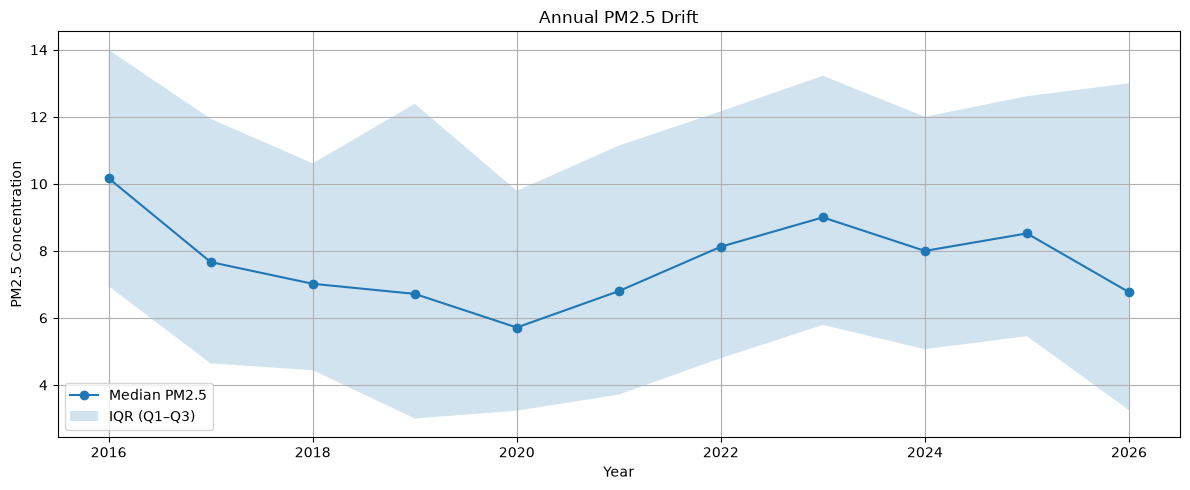

In [36]:
# Group observations by month
monthly_drift = df_valid.groupby(
    df_valid["date"].dt.to_period("M")
).agg(
    Median=("pm25", "median"),
    Q1=("pm25", lambda x: x.quantile(0.25)),
    Q3=("pm25", lambda x: x.quantile(0.75)),
    Count=("pm25", "count"),
    Above_25=("pm25", lambda x: (x > 25).sum()),
    Above_50=("pm25", lambda x: (x > 50).sum())
)

# Calculate IQR
monthly_drift["IQR"] = monthly_drift["Q3"] - monthly_drift["Q1"]

# Calculate percentages
monthly_drift["Above_25_Percent"] = (
    monthly_drift["Above_25"] / monthly_drift["Count"] * 100
)

monthly_drift["Above_50_Percent"] = (
    monthly_drift["Above_50"] / monthly_drift["Count"] * 100
)

print(monthly_drift.head(10).round(2))

# Group observations by year
annual_drift = df_valid.groupby(
    df_valid["date"].dt.year
).agg(
    Median=("pm25", "median"),
    Q1=("pm25", lambda x: x.quantile(0.25)),
    Q3=("pm25", lambda x: x.quantile(0.75)),
    Count=("pm25", "count"),
    Above_25=("pm25", lambda x: (x > 25).sum()),
    Above_50=("pm25", lambda x: (x > 50).sum())
)

# Calculate IQR
annual_drift["IQR"] = annual_drift["Q3"] - annual_drift["Q1"]

# Calculate percentages
annual_drift["Above_25_Percent"] = (
    annual_drift["Above_25"] / annual_drift["Count"] * 100
)

annual_drift["Above_50_Percent"] = (
    annual_drift["Above_50"] / annual_drift["Count"] * 100
)

print(annual_drift.round(2))

monthly_drift.to_csv(
    project_dir / "results" / "exploration" / "monthly_pm25_drift.csv"
)

annual_drift.to_csv(
    project_dir / "results" / "exploration" / "annual_pm25_drift.csv"
)

print("Monthly and annual PM2.5 drift results saved successfully.")

plt.figure(figsize=(12, 5))

plt.plot(
    annual_drift.index,
    annual_drift["Median"],
    marker="o",
    label="Median PM2.5"
)

plt.fill_between(
    annual_drift.index,
    annual_drift["Q1"],
    annual_drift["Q3"],
    alpha=0.2,
    label="IQR (Q1–Q3)"
)

plt.title("Annual PM2.5 Drift")
plt.xlabel("Year")
plt.ylabel("PM2.5 Concentration")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    figures_dir / "annual_pm25_drift.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [37]:
# Variables to analyze
temporal_variables = [
    "pm25",
    "AOD",
    "NO2",
    "CO",
    "O3",
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v"
]

# Calculate monthly averages
monthly_patterns = (
    df_valid
    .set_index("date")[temporal_variables]
    .resample("ME")
    .mean()
)

print(monthly_patterns.head(12).round(2))

monthly_patterns.to_csv(
    project_dir / "results" / "exploration" / "monthly_atmospheric_patterns.csv"
)

print("Monthly atmospheric patterns saved successfully.")

# Create a copy of the valid dataset
df_seasonal = df_valid.copy()

# Extract month
df_seasonal["month"] = df_seasonal["date"].dt.month

# Assign seasons
season_mapping = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Autumn",
    10: "Autumn",
    11: "Autumn"
}

df_seasonal["Season"] = df_seasonal["month"].map(season_mapping)

seasonal_patterns = (
    df_seasonal
    .groupby("Season")[temporal_variables]
    .mean()
)

# Keep seasons in chronological order
seasonal_patterns = seasonal_patterns.reindex(
    ["Winter", "Spring", "Summer", "Autumn"]
)

print(seasonal_patterns.round(2))

seasonal_patterns.to_csv(
    project_dir / "results" / "exploration" / "seasonal_atmospheric_patterns.csv"
)

print("Seasonal atmospheric patterns saved successfully.")


             pm25   AOD  NO2  CO  O3  temperature_celsius  pressure_mb  \
date                                                                     
2016-11-30   4.85  0.15  NaN NaN NaN                 9.52       982.66   
2016-12-31  11.11  0.14  NaN NaN NaN                10.57       996.24   
2017-01-31   7.52  0.08  NaN NaN NaN                 8.08       998.40   
2017-02-28  12.10  0.14  NaN NaN NaN                 9.73       991.74   
2017-03-31   9.86  0.13  NaN NaN NaN                13.23       994.05   
2017-04-30   9.23  0.14  NaN NaN NaN                14.21       987.84   
2017-05-31   7.55  0.19  NaN NaN NaN                19.78       989.47   
2017-06-30   7.49  0.17  NaN NaN NaN                23.90       988.44   
2017-07-31   7.60  0.19  NaN NaN NaN                24.80       988.04   
2017-08-31    NaN   NaN  NaN NaN NaN                  NaN          NaN   
2017-09-30   9.03  0.23  NaN NaN NaN                20.45       991.80   
2017-10-31   9.80  0.14  NaN NaN NaN  

In [38]:
# Variables used for lead-lag analysis
lead_lag_variables = [
    "AOD",
    "NO2",
    "CO",
    "O3",
    "temperature_celsius",
    "wind_u",
    "wind_v"
]

# Calculate daily averages
daily_variables = (
    df_valid
    .groupby("date")[["pm25"] + lead_lag_variables]
    .mean()
    .sort_index()
)

# Calculate wind speed from its two components
daily_variables["wind_speed"] = np.sqrt(
    daily_variables["wind_u"] ** 2 +
    daily_variables["wind_v"] ** 2
)

# Create a complete daily calendar without filling missing observations
full_dates = pd.date_range(
    start=daily_variables.index.min(),
    end=daily_variables.index.max(),
    freq="D"
)

daily_variables = daily_variables.reindex(full_dates)

print(daily_variables.head())
print("\nTotal calendar days:", len(daily_variables))
print("Days with missing PM2.5:", daily_variables["pm25"].isna().sum())

# Variables to compare with PM2.5
predictors = [
    "AOD",
    "NO2",
    "CO",
    "O3",
    "temperature_celsius",
    "wind_speed"
]

lead_lag_results = []

for variable in predictors:

    for lag in range(-7, 8):

        shifted_variable = daily_variables[variable].shift(lag)

        # Keep only dates where both values are available
        valid_pairs = pd.concat(
            [
                daily_variables["pm25"],
                shifted_variable
            ],
            axis=1
        ).dropna()

        correlation = valid_pairs.iloc[:, 0].corr(
            valid_pairs.iloc[:, 1],
            method="spearman"
        )

        lead_lag_results.append({
            "Variable": variable,
            "Lag_Days": lag,
            "Spearman_Correlation": correlation,
            "Number_of_Pairs": len(valid_pairs)
        })

lead_lag_df = pd.DataFrame(lead_lag_results)

print(lead_lag_df.round(3).to_string(index=False))

lead_lag_df.to_csv(
    project_dir / "results" / "exploration" / "lead_lag_correlations.csv",
    index=False
)

print("Lead-lag correlation results saved successfully.")


                pm25     AOD  NO2  CO  O3  temperature_celsius    wind_u  \
2016-11-25  7.208333  0.0665  NaN NaN NaN             7.872208  0.506729   
2016-11-26       NaN     NaN  NaN NaN NaN                  NaN       NaN   
2016-11-27       NaN     NaN  NaN NaN NaN                  NaN       NaN   
2016-11-28       NaN     NaN  NaN NaN NaN                  NaN       NaN   
2016-11-29       NaN     NaN  NaN NaN NaN                  NaN       NaN   

              wind_v  wind_speed  
2016-11-25  0.071342    0.511727  
2016-11-26       NaN         NaN  
2016-11-27       NaN         NaN  
2016-11-28       NaN         NaN  
2016-11-29       NaN         NaN  

Total calendar days: 3420
Days with missing PM2.5: 1121
           Variable  Lag_Days  Spearman_Correlation  Number_of_Pairs
                AOD        -7                -0.070             1998
                AOD        -6                -0.053             1974
                AOD        -5                -0.042             1985


In [39]:
# Prepare temporal summary

temporal_summary = pd.DataFrame({
    "Metric": [
        "Number of observed dates",
        "Number of missing calendar dates",
        "Number of continuous periods",
        "Longest continuous period (days)",
        "Longest period start",
        "Longest period end",
        "ADF statistic",
        "ADF p-value",
        "Number of observations used in ADF"
    ],
    "Value": [
        len(daily_pm25),
        (pd.date_range(
            daily_pm25.index.min(),
            daily_pm25.index.max(),
            freq="D"
        ).difference(daily_pm25.index)).size,
        len(continuous_periods),
        int(continuous_periods.iloc[0]["Number_of_Days"]),
        str(continuous_periods.iloc[0]["Start_Date"].date()),
        str(continuous_periods.iloc[0]["End_Date"].date()),
        round(adf_result[0], 4),
        round(adf_result[1], 6),
        adf_result[3]
    ]
})

print(temporal_summary.to_string(index=False))

temporal_summary.to_csv(
    project_dir / "results" / "exploration" / "Exploratory_temporal.csv",
    index=False
)

print("Exploratory_temporal.csv saved successfully.")


                            Metric      Value
          Number of observed dates       2299
  Number of missing calendar dates       1121
      Number of continuous periods        235
  Longest continuous period (days)        209
              Longest period start 2024-07-31
                Longest period end 2025-02-24
                     ADF statistic    -8.7943
                       ADF p-value        0.0
Number of observations used in ADF        208
Exploratory_temporal.csv saved successfully.


In [40]:
# Extract Ljung-Box results
ljung_box_summary = ljung_box_result.reset_index()

ljung_box_summary.columns = [
    "Lag",
    "Ljung_Box_Statistic",
    "Ljung_Box_p_value"
]

print(ljung_box_summary.round(4))

ljung_box_summary.to_csv(
    exploration_dir / "ljung_box_results.csv",
    index=False
)

print("Ljung-Box results saved.")

adf_summary = pd.DataFrame({
    "ADF_Statistic": [adf_result[0]],
    "p_value": [adf_result[1]],
    "Used_Lags": [adf_result[2]],
    "Observations": [adf_result[3]]
})

adf_summary.to_csv(
    exploration_dir / "adf_results.csv",
    index=False
)

print("ADF results saved.")


   Lag  Ljung_Box_Statistic  Ljung_Box_p_value
0    7              55.7356                0.0
1   14              62.8945                0.0
2   30              79.3103                0.0
Ljung-Box results saved.
ADF results saved.


## 6. Spatial Exploration


Number of unique stations: 91
Latitude range:
36.13331699932336 to 43.5302972250095
Longitude range:
-5.663499999930786 to 9.136389000276088


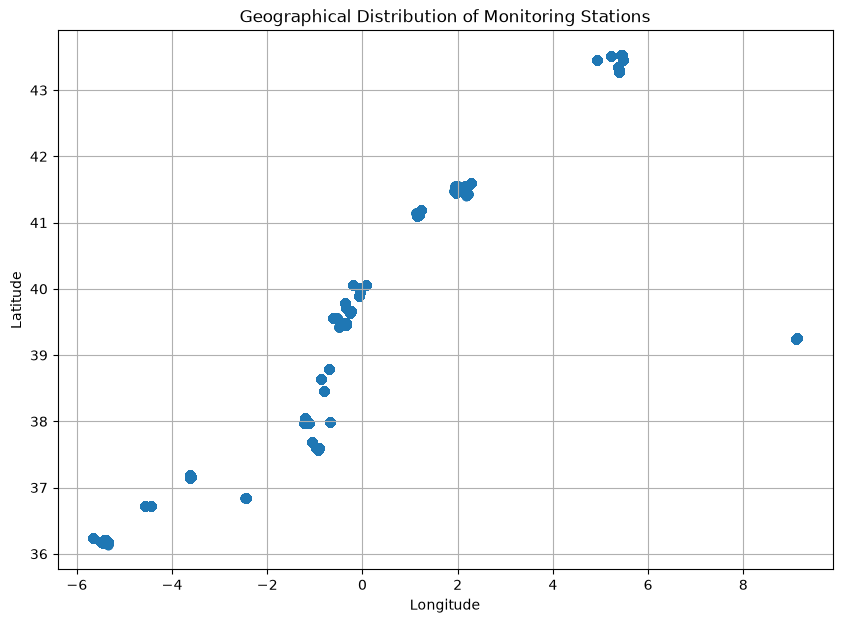

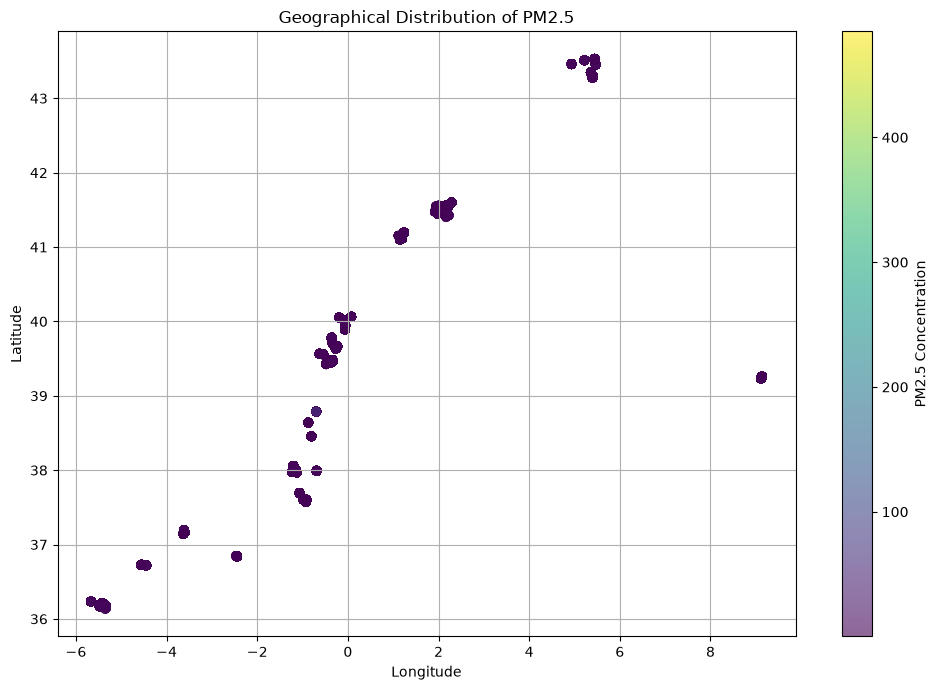

In [41]:
print("Number of unique stations:", df_valid["sensor_name"].nunique())

print("Latitude range:")
print(df_valid["latitude"].min(), "to", df_valid["latitude"].max())

print("Longitude range:")
print(df_valid["longitude"].min(), "to", df_valid["longitude"].max())

plt.figure(figsize=(10, 7))

plt.scatter(
    df_valid["longitude"],
    df_valid["latitude"],
    alpha=0.5
)

plt.title("Geographical Distribution of Monitoring Stations")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.grid()
plt.show()


fig, ax = plt.subplots(figsize=(10, 7))

scatter = ax.scatter(
    df_valid["longitude"],
    df_valid["latitude"],
    c=df_valid["pm25"],
    cmap="viridis",
    alpha=0.6
)

plt.colorbar(scatter, ax=ax, label="PM2.5 Concentration")

ax.set_title("Geographical Distribution of PM2.5")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

ax.grid()
plt.tight_layout()

# Save figure
fig.savefig(
    figures_dir / "spatial_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Top 10 stations with highest average PM2.5:
sensor_name
Gibraltar                        44.944869
Barcelona - Porta - Can Dragó    15.021562
HOSTELERÍA                       14.570939
PUENTE MAYORGA                   14.542355
FR03006                          14.346392
Albors - Valencia                14.269242
SAN BASILIO                      14.133745
CENCA1                           13.905287
Mollet del Vallès                13.571429
La Sagrera                       13.190455
Name: pm25, dtype: float64

Top 10 stations with lowest average PM2.5:
sensor_name
CENMO1                           6.389472
Terrassa                         6.369048
COLEGIO (S1)                     6.368116
E2: ALCORNOCALES                 5.566588
BURRIANA                         5.252133
BENICASSIM                       4.991778
ALGAR DE PALÀNCIA                4.649114
ALBALAT DELS TARONGERS           3.744186
CASTELLÓ-PENYETA                 3.243966
Barcelona - Camp d'en Grassot    0.622917
Name: pm25,

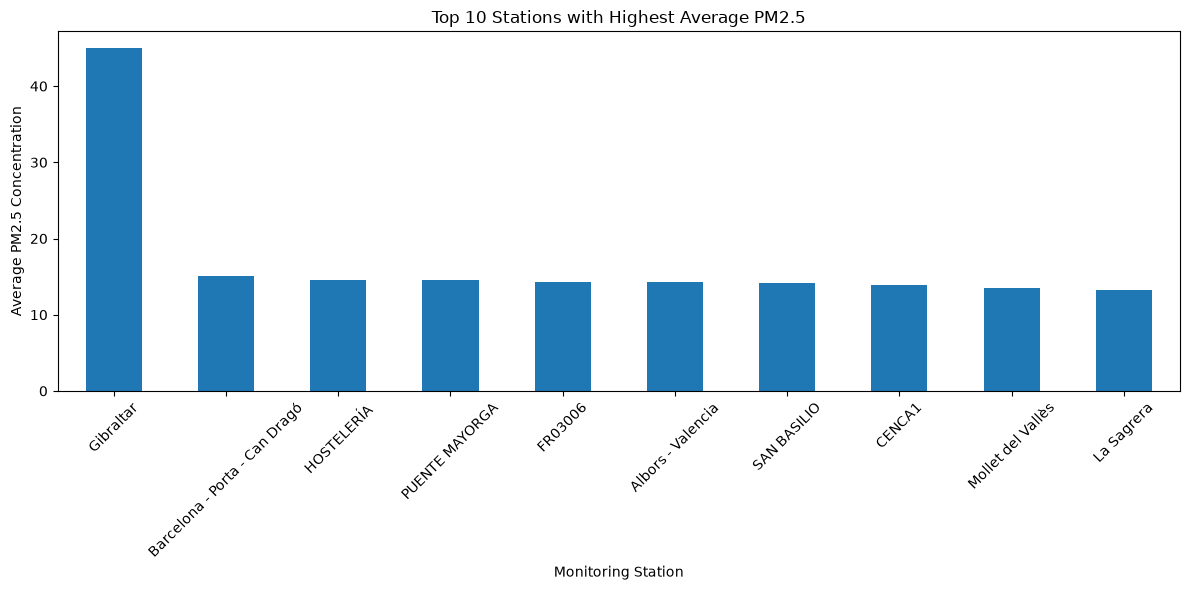

In [42]:
station_pm25 = df_valid.groupby("sensor_name")["pm25"].mean()

station_pm25 = station_pm25.sort_values(ascending=False)

print("Top 10 stations with highest average PM2.5:")
print(station_pm25.head(10))

print("\nTop 10 stations with lowest average PM2.5:")
print(station_pm25.tail(10))

plt.figure(figsize=(12, 6))

station_pm25.head(10).plot(kind="bar")

plt.title("Top 10 Stations with Highest Average PM2.5")
plt.xlabel("Monitoring Station")
plt.ylabel("Average PM2.5 Concentration")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    figures_dir / "station_pm25_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [43]:

# Check whether each ID is linked to one station name and location

id_check = df_valid.groupby("id").agg(
    sensor_names=("sensor_name", "nunique"),
    locations=("latitude", "nunique"),
    rows=("id", "size")
)

print("IDs linked to multiple station names or locations:")
print(
    id_check[
        (id_check["sensor_names"] > 1) |
        (id_check["locations"] > 1)
    ]
)

# Check whether one station name is linked to multiple IDs

name_check = df_valid.groupby("sensor_name").agg(
    ids=("id", "nunique"),
    locations=("latitude", "nunique"),
    rows=("sensor_name", "size")
)

print("\nStation names linked to multiple IDs:")
print(name_check[name_check["ids"] > 1])

# Check repeated records for the same ID and date

print("\nDuplicate ID-date combinations:")
print(df_valid.duplicated(subset=["id", "date"]).sum())


stations_to_check = [
    "LA ALJORRA",
    "MOLINA DE SEGURA",
    "MOMPEAN",
    "SAN BASILIO"
]

station_mapping = (
    df_valid[df_valid["sensor_name"].isin(stations_to_check)]
    .groupby(["sensor_name", "id"])
    .agg(
        latitude=("latitude", "mean"),
        longitude=("longitude", "mean"),
        first_date=("date", "min"),
        last_date=("date", "max"),
        rows=("id", "size")
    )
    .reset_index()
)

print(station_mapping.to_string(index=False))


IDs linked to multiple station names or locations:
Empty DataFrame
Columns: [sensor_names, locations, rows]
Index: []

Station names linked to multiple IDs:
                  ids  locations  rows
sensor_name                           
LA ALJORRA          2          2   528
MOLINA DE SEGURA    2          2   490
MOMPEAN             2          2   894
SAN BASILIO         2          2   579

Duplicate ID-date combinations:
0
     sensor_name  id  latitude  longitude first_date  last_date  rows
      LA ALJORRA  84 37.693611  -1.064722 2023-12-30 2024-08-28   169
      LA ALJORRA  86 37.692500  -1.065900 2024-09-01 2026-02-09   359
MOLINA DE SEGURA 105 38.057300  -1.204700 2024-01-28 2024-08-30   149
MOLINA DE SEGURA 107 38.057373  -1.204813 2024-08-30 2026-02-09   341
         MOMPEAN  83 37.603056  -0.975278 2020-12-30 2024-08-28   540
         MOMPEAN  87 37.601800  -0.976200 2024-08-31 2026-02-09   354
     SAN BASILIO 104 37.993611  -1.144722 2023-09-20 2024-08-30   235
     SAN BASIL

In [44]:


df_gee = pd.read_csv(project_dir / "data" / "raw" / "gee_features_daily.csv")

df_gee["date"] = pd.to_datetime(df_gee["date"])

print("GEE dataset shape:", df_gee.shape)
print(df_gee.head())


print("Number of GEE IDs:", df_gee["id"].nunique())

print("\nDuplicate ID-date combinations:")
print(df_gee.duplicated(subset=["id", "date"]).sum())

gee_mapping = df_gee.groupby("id").agg(
    latitudes=("lat", "nunique"),
    longitudes=("lon", "nunique"),
    rows=("id", "size"),
    first_date=("date", "min"),
    last_date=("date", "max")
)

print("\nIDs with multiple coordinates:")
print(
    gee_mapping[
        (gee_mapping["latitudes"] > 1) |
        (gee_mapping["longitudes"] > 1)
    ].to_string()
)

print("\nFirst 15 GEE IDs:")
print(gee_mapping.head(15).to_string())


# Keep only the GEE columns needed for matching
gee_reference = df_gee[
    ["id", "date", "lat", "lon"]
].copy()

# Match using ID and date
matching_check = df_valid.merge(
    gee_reference,
    on=["id", "date"],
    how="left",
    indicator=True,
    validate="many_to_one"
)

# Check whether every PM2.5 row has a GEE match
print("Matching results:")
print(matching_check["_merge"].value_counts())

# Calculate coordinate differences for matched rows
matched = matching_check[matching_check["_merge"] == "both"].copy()

matched["latitude_difference"] = (
    matched["latitude"] - matched["lat"]
).abs()

matched["longitude_difference"] = (
    matched["longitude"] - matched["lon"]
).abs()

print("\nCoordinate difference statistics:")
print(
    matched[
        ["latitude_difference", "longitude_difference"]
    ].describe()
)

# Check the approximate 0.25-degree tolerance
outside_tolerance = (
    (matched["latitude_difference"] > 0.25) |
    (matched["longitude_difference"] > 0.25)
)

print("\nMatched rows outside 0.25-degree coordinate tolerance:")
print(outside_tolerance.sum())


GEE dataset shape: (164208, 13)
        date         datetime_utc  id        lat       lon  \
0 2016-11-21  2016-11-21 00:00:00  90  39.235833  9.115000   
1 2016-11-21  2016-11-21 00:00:00  91  39.260556  9.136389   
2 2016-11-22  2016-11-22 00:00:00  28  36.203880 -5.383710   
3 2016-11-22  2016-11-22 00:00:00  40  41.426100  2.148000   
4 2016-11-22  2016-11-22 00:00:00  51  41.424066  2.185757   

   temperature_celsius  pressure_mb    wind_u    wind_v  NO2  CO  O3    AOD  
0            15.842538   994.344313 -2.613506  2.663921  NaN NaN NaN  0.207  
1            15.842538   994.344313 -2.613506  2.663921  NaN NaN NaN  0.207  
2            13.119320   989.320581  1.555070  0.348089  NaN NaN NaN  0.277  
3            15.658871   997.975164 -1.073064  0.549383  NaN NaN NaN  0.197  
4            15.658871   997.975164 -1.073064  0.549383  NaN NaN NaN  0.197  
Number of GEE IDs: 100

Duplicate ID-date combinations:
0

IDs with multiple coordinates:
Empty DataFrame
Columns: [latitudes, 

In [45]:
# Count observations for each monitoring station
station_counts = df_valid["sensor_name"].value_counts()

print("Number of unique stations:", df_valid["sensor_name"].nunique())

print("\nObservations per station:")
print(station_counts.describe())

print("\nTop 10 stations:")
print(station_counts.head(10))

station_counts.to_csv(
    project_dir / "results" / "exploration" / "station_counts.csv",
    header=["Number of Observations"]
)

print("Station counts saved successfully!")


Number of unique stations: 91

Observations per station:
count      91.000000
mean      450.362637
std       272.658538
min         4.000000
25%       220.000000
50%       468.000000
75%       677.500000
max      1042.000000
Name: count, dtype: float64

Top 10 stations:
sensor_name
CENMO1                    1042
CENCA1                    1037
MOMPEAN                    894
ALBALAT DELS TARONGERS     798
SAGUNT CEA                 797
CARRANQUE                  784
TORREVIEJA                 780
ALGAR DE PALÀNCIA          771
BENICASSIM                 770
ALCORA                     761
Name: count, dtype: int64
Station counts saved successfully!


In [46]:
station_coverage = (
    df_valid.groupby("sensor_name")
    .agg(
        Number_of_Observations=("pm25", "count"),
        First_Date=("date", "min"),
        Last_Date=("date", "max"),
        Number_of_Days=("date", "nunique")
    )
    .sort_values("Number_of_Observations", ascending=False)
)

print("Number of monitoring stations:", len(station_coverage))

print("\nStation coverage statistics:")
print(station_coverage["Number_of_Observations"].describe().round(2))

print("\nTop 10 stations:")
print(station_coverage.head(10))

station_coverage.to_csv(
    project_dir / "results" / "exploration" / "station_temporal_coverage.csv"
)

print("Station temporal coverage saved successfully!")


Number of monitoring stations: 91

Station coverage statistics:
count      91.00
mean      450.36
std       272.66
min         4.00
25%       220.00
50%       468.00
75%       677.50
max      1042.00
Name: Number_of_Observations, dtype: float64

Top 10 stations:
                        Number_of_Observations First_Date  Last_Date  \
sensor_name                                                            
CENMO1                                    1042 2020-05-06 2026-04-06   
CENCA1                                    1037 2020-05-06 2026-03-09   
MOMPEAN                                    894 2020-12-30 2026-02-09   
ALBALAT DELS TARONGERS                     798 2016-12-02 2022-11-06   
SAGUNT CEA                                 797 2016-12-02 2022-11-12   
CARRANQUE                                  784 2022-01-11 2026-01-12   
TORREVIEJA                                 780 2020-01-06 2024-02-12   
ALGAR DE PALÀNCIA                          771 2016-12-02 2023-04-12   
BENICASSIM       

## 7. Missingness Analysis


,Missing Values,Percentage
date,0,0.000000
datetime_utc,0,0.000000
id,0,0.000000
latitude,0,0.000000
longitude,0,0.000000
temperature_celsius,0,0.000000
pressure_mb,0,0.000000
wind_u,0,0.000000
wind_v,0,0.000000
NO2,2410,5.776883


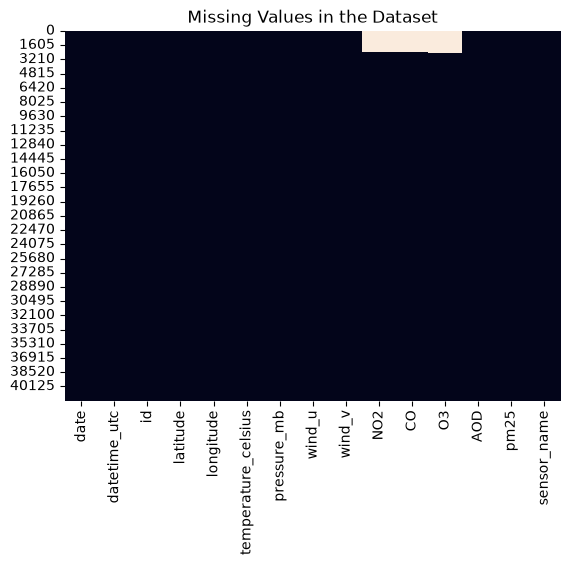

In [47]:
missing_data = pd.DataFrame({
    "Missing Values": df_raw.isnull().sum(),
    "Percentage": (df_raw.isnull().sum() / len(df_raw)) * 100
})

display(missing_data)


sns.heatmap(df_raw.isnull(), cbar=False)
plt.title("Missing Values in the Dataset")
plt.show()


In [48]:
print(df_valid.isnull().sum())


date                      0
datetime_utc              0
id                        0
latitude                  0
longitude                 0
temperature_celsius       0
pressure_mb               0
wind_u                    0
wind_v                    0
NO2                    2407
CO                     2407
O3                     2448
AOD                       0
pm25                      0
sensor_name               0
season                    0
dtype: int64


In [49]:
raw_missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum() / len(df)) * 100
})
raw_missing.to_csv(exploration_dir / "missing_values_raw.csv")
print("Raw missing-value report saved.")


Raw missing-value report saved.


In [50]:
# Work on a copy of the valid dataset
df_missing = df_valid.copy()

# Extract year and month
df_missing["Year_Month"] = df_missing["date"].dt.to_period("M")

# Variables to analyze
missing_variables = ["NO2", "CO", "O3"]

# Calculate monthly missingness
monthly_missingness = (
    df_missing
    .groupby("Year_Month")[missing_variables]
    .agg(
        lambda x: x.isna().mean() * 100
    )
)

print(monthly_missingness.head(15).round(2))

monthly_missingness.to_csv(
    exploration_dir / "monthly_missingness.csv"
)

print("Monthly missingness results saved.")


              NO2     CO     O3
Year_Month                     
2016-11     100.0  100.0  100.0
2016-12     100.0  100.0  100.0
2017-01     100.0  100.0  100.0
2017-02     100.0  100.0  100.0
2017-03     100.0  100.0  100.0
2017-04     100.0  100.0  100.0
2017-05     100.0  100.0  100.0
2017-06     100.0  100.0  100.0
2017-07     100.0  100.0  100.0
2017-09     100.0  100.0  100.0
2017-10     100.0  100.0  100.0
2017-11     100.0  100.0  100.0
2017-12     100.0  100.0  100.0
2018-01     100.0  100.0  100.0
2018-03     100.0  100.0  100.0
Monthly missingness results saved.


In [51]:
station_missingness = (
    df_missing
    .groupby("sensor_name")[missing_variables]
    .agg(
        lambda x: x.isna().mean() * 100
    )
)

# Add number of observations per station
station_missingness["Observation_Count"] = (
    df_missing.groupby("sensor_name").size()
)

# Sort by highest missingness in NO2
station_missingness = station_missingness.sort_values(
    "NO2",
    ascending=False
)

print(station_missingness.head(15).round(2))

station_missingness.to_csv(
    exploration_dir / "station_missingness.csv"
)

print("Station missingness results saved.")


                           NO2     CO     O3  Observation_Count
sensor_name                                                    
FR03030                  55.48  55.48  56.18                283
FR03006                  47.31  47.31  47.69                260
FR03043                  46.47  46.47  47.21                269
FR03029                  45.85  45.85  46.64                253
VALÈNCIA-PISTA DE SILLA  21.48  21.48  21.90                717
QUART DE POBLET          21.48  21.48  21.90                717
ALMASSORA-C. P. OCHANDO  21.11  21.11  21.38                739
VALÈNCIA-POLITÈCNIC      20.94  20.94  21.35                726
ALGAR DE PALÀNCIA        20.75  20.75  21.01                771
BENICASSIM               20.65  20.65  21.04                770
ELDA-LACY                20.63  20.63  21.05                727
ALCORA                   20.37  20.37  20.76                761
ALBALAT DELS TARONGERS   19.92  19.92  20.05                798
SAGUNT CEA               19.82  19.82  2

## 8. Data Preprocessing


Build the model-ready feature table after temporal analyses have added the calendar-year feature. No imputer is fitted in this section.


In [52]:
df_model = df[(df["pm25"] > 0) & (df["pm25"] < 500)].copy()

print("Original dataset:", df.shape)
print("Dataset for preprocessing:", df_model.shape)

df_model = df_model.sort_values(
    by=["date", "sensor_name"]
).reset_index(drop=True)

print(df_model.isnull().sum())

missing_percent = (df_model.isnull().sum() / len(df_model)) * 100
print(missing_percent[missing_percent > 0].round(2))

missing_before_imputation = pd.DataFrame({
    "Missing Values": df_model.isnull().sum(),
    "Percentage": (df_model.isnull().sum() / len(df_model)) * 100
})
missing_before_imputation.to_csv(exploration_dir / "missing_values_before_imputation.csv")
print("Pre-imputation missing-value report saved.")

print(df_model["pm25"].describe())


Original dataset: (41718, 16)
Dataset for preprocessing: (40983, 16)
date                      0
datetime_utc              0
id                        0
latitude                  0
longitude                 0
temperature_celsius       0
pressure_mb               0
wind_u                    0
wind_v                    0
NO2                    2407
CO                     2407
O3                     2448
AOD                       0
pm25                      0
sensor_name               0
year                      0
dtype: int64
NO2    5.87
CO     5.87
O3     5.97
dtype: float64
Pre-imputation missing-value report saved.
count    40983.000000
mean         9.457765
std          9.729713
min          0.006667
25%          4.673864
50%          7.851176
75%         12.086667
max        484.981500
Name: pm25, dtype: float64


In [53]:
X = df_model.drop(columns=["pm25"])
y = df_model["pm25"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

X = X.drop(columns=["date", "datetime_utc", "sensor_name", "id"])

print("Final features:")
print(X.columns.tolist())

print("Features shape:", X.shape)


Features shape: (40983, 15)
Target shape: (40983,)
Final features:
['latitude', 'longitude', 'temperature_celsius', 'pressure_mb', 'wind_u', 'wind_v', 'NO2', 'CO', 'O3', 'AOD', 'year']
Features shape: (40983, 11)


## 9. Train/Test Split


The split is chronological by unique date. Preserve the raw train and test feature frames; create missingness indicators and fit median imputation on training data only.


In [54]:
# Sort the dataset by date
df_model = df_model.sort_values(
    ["date", "sensor_name"]
).reset_index(drop=True)

# Select the features again, keeping rows aligned
X = df_model.drop(
    columns=["pm25", "date", "datetime_utc", "sensor_name", "id"]
)

y = df_model["pm25"]

# Get unique dates
unique_dates = df_model["date"].drop_duplicates().sort_values()

# Find the 80% date boundary
split_index = int(len(unique_dates) * 0.8)
split_date = unique_dates.iloc[split_index]

# Split using the date boundary
train_mask = df_model["date"] < split_date
test_mask = df_model["date"] >= split_date

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

train_data = df_model.loc[train_mask].copy()
X_train_raw = X_train.copy()
X_test_raw = X_test.copy()

assert df_model.loc[train_mask, "date"].max() < df_model.loc[test_mask, "date"].min()

print("Split date:", split_date)
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("Training dates:",
      df_model.loc[train_mask, "date"].min(),
      "to",
      df_model.loc[train_mask, "date"].max())

print("Testing dates:",
      df_model.loc[test_mask, "date"].min(),
      "to",
      df_model.loc[test_mask, "date"].max())


Split date: 2024-12-08 00:00:00
Training set: (30651, 11)
Testing set: (10332, 11)
Training dates: 2016-11-25 00:00:00 to 2024-12-07 00:00:00
Testing dates: 2024-12-08 00:00:00 to 2026-04-06 00:00:00


In [55]:
print(df_model[["date", "pm25"]].head())
print(df_model[["date", "pm25"]].tail())


        date       pm25
0 2016-11-25  11.666667
1 2016-11-25   2.750000
2 2016-11-30   2.400000
3 2016-11-30   2.600000
4 2016-12-02   6.200000
            date      pm25
40978 2026-04-06  5.000000
40979 2026-04-06  6.000000
40980 2026-04-06  8.500000
40981 2026-04-06  1.429167
40982 2026-04-06  5.904167


In [56]:
print("Training dataset shape:", X_train.shape)
print("Testing dataset shape:", X_test.shape)

print("\nMissing values in training:")
print(X_train[["NO2", "CO", "O3"]].isna().sum())

print("\nMissing values in testing:")
print(X_test[["NO2", "CO", "O3"]].isna().sum())

missing_variables = ["NO2", "CO", "O3"]

for variable in missing_variables:

    X_train[variable + "_missing"] = (
        X_train[variable].isna().astype(int)
    )

    X_test[variable + "_missing"] = (
        X_test[variable].isna().astype(int)
    )

print("Missingness indicators created.")

print(X_train[
    ["NO2_missing", "CO_missing", "O3_missing"]
].sum())


Training dataset shape: (30651, 11)
Testing dataset shape: (10332, 11)

Missing values in training:
NO2    2407
CO     2407
O3     2448
dtype: int64

Missing values in testing:
NO2    0
CO     0
O3     0
dtype: int64
Missingness indicators created.
NO2_missing    2407
CO_missing     2407
O3_missing     2448
dtype: int64


In [57]:

imputer = SimpleImputer(strategy="median")

X_train[missing_variables] = imputer.fit_transform(
    X_train[missing_variables]
)

X_test[missing_variables] = imputer.transform(
    X_test[missing_variables]
)

print("Median imputation completed.")

print("Missing values after imputation:")

print("\nTraining:")
print(X_train.isna().sum().sum())

print("\nTesting:")
print(X_test.isna().sum().sum())

print("\nTraining indicator totals:")
print(X_train[
    ["NO2_missing", "CO_missing", "O3_missing"]
].sum())


Median imputation completed.
Missing values after imputation:

Training:
0

Testing:
0

Training indicator totals:
NO2_missing    2407
CO_missing     2407
O3_missing     2448
dtype: int64


## 10. Temporal Cross-Validation


In [58]:


# Dates corresponding to X_train, in the same row order
train_dates = df_model.loc[train_mask, "date"].reset_index(drop=True)

# Create a complete daily calendar
calendar = pd.date_range(
    start=train_dates.min(),
    end=train_dates.max(),
    freq="D"
)

# 5 temporal folds with a 1-day gap
tscv = TimeSeriesSplit(n_splits=5, gap=1)

folds = []
fold_summary = []

for fold_number, (train_idx, val_idx) in enumerate(
    tscv.split(calendar), start=1
):
    fold_train_dates = calendar[train_idx]
    fold_val_dates = calendar[val_idx]

    # Convert calendar dates into row positions in X_train
    fold_train_mask = train_dates.isin(fold_train_dates).to_numpy()
    fold_val_mask = train_dates.isin(fold_val_dates).to_numpy()

    row_train_idx = np.flatnonzero(fold_train_mask)
    row_val_idx = np.flatnonzero(fold_val_mask)

    folds.append((row_train_idx, row_val_idx))

    fold_summary.append({
        "fold": fold_number,
        "train_rows": len(row_train_idx),
        "validation_rows": len(row_val_idx),
        "train_start": train_dates.iloc[row_train_idx].min(),
        "train_end": train_dates.iloc[row_train_idx].max(),
        "validation_start": train_dates.iloc[row_val_idx].min(),
        "validation_end": train_dates.iloc[row_val_idx].max()
    })

fold_summary_df = pd.DataFrame(fold_summary)

print(fold_summary_df.to_string(index=False))


for fold_number, (train_idx, val_idx) in enumerate(
    tscv.split(calendar), start=1
):
    calendar_train_end = calendar[train_idx[-1]]
    calendar_val_start = calendar[val_idx[0]]

    observed_train_end = train_dates[
        train_dates.isin(calendar[train_idx])
    ].max()

    observed_val_start = train_dates[
        train_dates.isin(calendar[val_idx])
    ].min()

    print(f"\nFold {fold_number}")
    print("Calendar training end:", calendar_train_end.date())
    print("Calendar validation start:", calendar_val_start.date())
    print(
        "Calendar gap:",
        (calendar_val_start - calendar_train_end).days - 1,
        "day(s)"
    )
    print("Last observed training date:", observed_train_end.date())
    print("First observed validation date:", observed_val_start.date())


 fold  train_rows  validation_rows train_start  train_end validation_start validation_end
    1        2339             1718  2016-11-25 2018-03-23       2018-05-29     2019-07-31
    2        4053             3234  2016-11-25 2019-07-30       2019-08-01     2020-12-01
    3        7289             6760  2016-11-25 2020-11-30       2020-12-02     2022-04-04
    4       14049             5644  2016-11-25 2022-04-03       2022-04-05     2023-08-06
    5       19664            10956  2016-11-25 2023-08-05       2023-08-07     2024-12-07

Fold 1
Calendar training end: 2018-03-28
Calendar validation start: 2018-03-30
Calendar gap: 1 day(s)
Last observed training date: 2018-03-23
First observed validation date: 2018-05-29

Fold 2
Calendar training end: 2019-07-30
Calendar validation start: 2019-08-01
Calendar gap: 1 day(s)
Last observed training date: 2019-07-30
First observed validation date: 2019-08-01

Fold 3
Calendar training end: 2020-11-30
Calendar validation start: 2020-12-02
Calendar

In [59]:
fold_results = []

for fold, (train_idx, val_idx) in enumerate(folds, 1):
    X_fold_train = X_train_raw.iloc[train_idx].copy()
    X_fold_val = X_train_raw.iloc[val_idx].copy()
    imputer = SimpleImputer(
        strategy="median",
        keep_empty_features=True
    )
    X_fold_train[missing_variables] = imputer.fit_transform(
        X_fold_train[missing_variables]
    )
    X_fold_val[missing_variables] = imputer.transform(
        X_fold_val[missing_variables]
    )
    fold_results.append({
        "Fold": fold,
        "Train_Rows": len(X_fold_train),
        "Validation_Rows": len(X_fold_val),
        "Train_Missing": X_fold_train.isna().sum().sum(),
        "Validation_Missing": X_fold_val.isna().sum().sum()
    })

fold_summary = pd.DataFrame(fold_results)
print(fold_summary)


   Fold  Train_Rows  Validation_Rows  Train_Missing  Validation_Missing
0     1        2339             1718              0                   0
1     2        4053             3234              0                   0
2     3        7289             6760              0                   0
3     4       14049             5644              0                   0
4     5       19664            10956              0                   0


## 11. Spatial and Random Validation


In [60]:

# Use training period only
spatial_data = df_model.loc[train_mask].copy().reset_index(drop=True)

spatial_features = [
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v",
    "NO2",
    "CO",
    "O3",
    "AOD"
]

X_spatial = spatial_data[spatial_features].copy()
y_spatial = spatial_data["pm25"]
station_groups = spatial_data["id"]

gkf = GroupKFold(n_splits=5)

spatial_results = []

for fold, (train_idx, val_idx) in enumerate(
    gkf.split(X_spatial, y_spatial, groups=station_groups), 1
):

    X_tr = X_spatial.iloc[train_idx].copy()
    X_val = X_spatial.iloc[val_idx].copy()

    for col in ["NO2", "CO", "O3"]:
        X_tr[col + "_missing"] = X_tr[col].isna().astype(int)
        X_val[col + "_missing"] = X_val[col].isna().astype(int)

    imputer = SimpleImputer(
        strategy="median",
        keep_empty_features=True
    )

    missing_cols = ["NO2", "CO", "O3"]

    X_tr[missing_cols] = imputer.fit_transform(X_tr[missing_cols])
    X_val[missing_cols] = imputer.transform(X_val[missing_cols])

    spatial_results.append({
        "Fold": fold,
        "Train_Rows": len(X_tr),
        "Validation_Rows": len(X_val),
        "Train_Stations": station_groups.iloc[train_idx].nunique(),
        "Validation_Stations": station_groups.iloc[val_idx].nunique(),
        "Train_Missing": X_tr.isna().sum().sum(),
        "Validation_Missing": X_val.isna().sum().sum()
    })

spatial_summary = pd.DataFrame(spatial_results)

print(spatial_summary)


   Fold  Train_Rows  Validation_Rows  Train_Stations  Validation_Stations  \
0     1       24500             6151              59                   14   
1     2       24503             6148              58                   15   
2     3       24511             6140              59                   14   
3     4       24553             6098              58                   15   
4     5       24537             6114              58                   15   

   Train_Missing  Validation_Missing  
0              0                   0  
1              0                   0  
2              0                   0  
3              0                   0  
4              0                   0  


In [61]:

print("Spatial validation summary calculated.")
print("Latest date used:", spatial_data["date"].max())


Spatial validation summary calculated.
Latest date used: 2024-12-07 00:00:00


In [62]:

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

random_results = []

for fold, (train_idx, val_idx) in enumerate(
    kf.split(X_train_raw), 1
):
    random_results.append({
        "Fold": fold,
        "Train_Rows": len(train_idx),
        "Validation_Rows": len(val_idx)
    })

random_summary = pd.DataFrame(random_results)

print(random_summary)


print("Random K-Fold summary calculated.")


   Fold  Train_Rows  Validation_Rows
0     1       24520             6131
1     2       24521             6130
2     3       24521             6130
3     4       24521             6130
4     5       24521             6130
Random K-Fold summary calculated.


## 12. Final Outputs and Verification


Final exports use the post-split, training-fitted imputation outputs and aligned targets/dates. Model-training cells are not run.


In [63]:
# Save the final feature matrices and their aligned targets and dates.
X_train.to_csv(
    processed_dir / "X_train_final.csv",
    index=False
)
X_test.to_csv(
    processed_dir / "X_test_final.csv",
    index=False
)

train_dates = df_model.loc[train_mask, "date"].reset_index(drop=True)
test_dates = df_model.loc[test_mask, "date"].reset_index(drop=True)

pd.DataFrame({
    "date": train_dates,
    "pm25": y_train.to_numpy()
}).to_csv(processed_dir / "y_train_final.csv", index=False)

pd.DataFrame({
    "date": test_dates,
    "pm25": y_test.to_numpy()
}).to_csv(processed_dir / "y_test_final.csv", index=False)

pd.DataFrame({"date": train_dates}).to_csv(
    processed_dir / "train_dates.csv",
    index=False
)
pd.DataFrame({"date": test_dates}).to_csv(
    processed_dir / "test_dates.csv",
    index=False
)

fold_data = {}
for i, (train_idx, val_idx) in enumerate(folds, start=1):
    fold_data[f"fold_{i}_train"] = train_idx
    fold_data[f"fold_{i}_validation"] = val_idx

np.savez_compressed(
    fold_dir / "temporal_cv_folds.npz",
    **fold_data
)
fold_summary_df.to_csv(
    fold_dir / "temporal_cv_summary.csv",
    index=False
)
fold_summary.to_csv(
    fold_dir / "fold_preprocessing_summary.csv",
    index=False
)
spatial_summary.to_csv(
    fold_dir / "spatial_cv_summary.csv",
    index=False
)
random_summary.to_csv(
    fold_dir / "random_kfold_summary.csv",
    index=False
)

print("Final preprocessing outputs saved successfully.")
print("Temporal, spatial, and random validation summaries saved successfully.")


Final preprocessing outputs saved successfully.
Temporal, spatial, and random validation summaries saved successfully.


In [64]:

# Reload saved files
Xtr_check = pd.read_csv(
    project_dir / "data" / "processed" / "X_train_final.csv"
)
Xte_check = pd.read_csv(
    project_dir / "data" / "processed" / "X_test_final.csv"
)
ytr_check = pd.read_csv(
    project_dir / "data" / "processed" / "y_train_final.csv"
)
yte_check = pd.read_csv(
    project_dir / "data" / "processed" / "y_test_final.csv"
)

# Verify shapes
print("X_train:", Xtr_check.shape)
print("X_test:", Xte_check.shape)
print("y_train:", ytr_check.shape)
print("y_test:", yte_check.shape)

# Verify missing values
print("\nMissing values:")
print("X_train:", Xtr_check.isnull().sum().sum())
print("X_test:", Xte_check.isnull().sum().sum())

# Verify target dates
print("\nTraining period:")
print(ytr_check["date"].min(), "to", ytr_check["date"].max())

print("\nTesting period:")
print(yte_check["date"].min(), "to", yte_check["date"].max())

# Verify saved CV folds
saved_folds = np.load(
    project_dir / "folds" / "temporal_cv_folds.npz"
)

print("\nSaved CV folds:")
for i in range(1, 6):
    train_idx = saved_folds[f"fold_{i}_train"]
    val_idx = saved_folds[f"fold_{i}_validation"]

    print(
        f"Fold {i}:",
        len(train_idx), "training rows,",
        len(val_idx), "validation rows"
    )


X_train: (30651, 14)
X_test: (10332, 14)
y_train: (30651, 2)
y_test: (10332, 2)

Missing values:
X_train: 0
X_test: 0

Training period:
2016-11-25 to 2024-12-07

Testing period:
2024-12-08 to 2026-04-06

Saved CV folds:
Fold 1: 2339 training rows, 1718 validation rows
Fold 2: 4053 training rows, 3234 validation rows
Fold 3: 7289 training rows, 6760 validation rows
Fold 4: 14049 training rows, 5644 validation rows
Fold 5: 19664 training rows, 10956 validation rows


In [65]:
print("FINAL PREPROCESSING CHECK")

print("\nTemporal CV:")
print(fold_summary)

print("\nSpatial CV:")
print(spatial_summary)

print("\nRandom K-Fold:")
print(random_summary)

print("\nFinal train shape:", X_train.shape)
print("Final test shape:", X_test.shape)

print("\nMissing values in final train:", X_train.isna().sum().sum())
print("Missing values in final test:", X_test.isna().sum().sum())


FINAL PREPROCESSING CHECK

Temporal CV:
   Fold  Train_Rows  Validation_Rows  Train_Missing  Validation_Missing
0     1        2339             1718              0                   0
1     2        4053             3234              0                   0
2     3        7289             6760              0                   0
3     4       14049             5644              0                   0
4     5       19664            10956              0                   0

Spatial CV:
   Fold  Train_Rows  Validation_Rows  Train_Stations  Validation_Stations  \
0     1       24500             6151              59                   14   
1     2       24503             6148              58                   15   
2     3       24511             6140              59                   14   
3     4       24553             6098              58                   15   
4     5       24537             6114              58                   15   

   Train_Missing  Validation_Missing  
0            

In [66]:
print("TEMPORAL EXPLORATION FILES\n")

for file in sorted(exploration_dir.glob("*.csv")):
    print("-", file.name)

print("PROCESSED DATA:")
for file in sorted(processed_dir.glob("*.csv")):
    print("-", file.name)

print("\nVALIDATION FILES:")
for file in sorted(fold_dir.glob("*.csv")):
    print("-", file.name)


TEMPORAL EXPLORATION FILES

- adf_results.csv
- adf_test.csv
- annual_pm25_drift.csv
- annual_pm25_statistics.csv
- cleaning_summary.csv
- daily_observation_statistics.csv
- descriptive_statistics.csv
- descriptive_statistics_raw.csv
- duplicate_summary.csv
- Exploratory_Data.csv
- Exploratory_temporal.csv
- lead_lag_correlations.csv
- ljung_box_results.csv
- ljung_box_test.csv
- missing_dates.csv
- missing_values_before_imputation.csv
- missing_values_raw.csv
- monthly_atmospheric_patterns.csv
- monthly_missingness.csv
- monthly_pm25_drift.csv
- monthly_pm25_statistics.csv
- pm25_descriptive_statistics_valid.csv
- seasonal_atmospheric_patterns.csv
- seasonal_correlations.csv
- seasonal_pm25_statistics.csv
- station_counts.csv
- station_missingness.csv
- station_temporal_coverage.csv
- timeseries_annual_summary.csv
- timeseries_ljung_box.csv
- timeseries_monthly_summary.csv
- timeseries_stationarity_tests.csv
- wind_aod_correlation.csv
PROCESSED DATA:
- test_dates.csv
- train_dates.csv

In [67]:
print("Latest date in spatial validation data:")
print(spatial_data["date"].max())

print("\nLatest date in training data:")
print(train_data["date"].max())

print("\nFinal test starts:")
print(pd.Timestamp("2024-12-08"))


Latest date in spatial validation data:
2024-12-07 00:00:00

Latest date in training data:
2024-12-07 00:00:00

Final test starts:
2024-12-08 00:00:00
